# Thu thập và khám phá dữ liệu TMDB + IMDb

**Cập nhật ngày 17/11/2026 theo bốn câu hỏi đã chốt.** CSV đầu vào là bản nhóm tải ngày 05/11/2026.
Notebook kiểm tra cấu trúc, chất lượng, phân phối và các mối liên hệ sơ bộ theo mục 3.2 của
[đề bài](../doc/CSC17104_2026_Final_Project.pdf).

Các bảng chất lượng đếm bản ghi raw. Phần quan hệ có mẫu riêng cho từng câu hỏi, kèm điều kiện
và số dòng trước, sau mỗi bước lọc. Phạm vi câu hỏi và người phụ trách được ghi tại
[QUESTIONS.md](../doc/QUESTIONS.md).

Chọn kernel **Python (movies-dataset)** và chạy lại toàn bộ notebook từ đầu. Notebook đọc CSV cục bộ,
thực hiện chuyển kiểu và lọc trong bộ nhớ. Các ghi chú và mã có hỗ trợ của Codex được ghi trong
[LLM_USAGE.md](../LLM_USAGE.md). Theo mục 6 của đề, nhóm cần hiểu mã, kiểm chứng kết quả
và tự viết phần phân tích, câu trả lời, reflection dùng trong bài nộp.

## 1. Nguồn và bối cảnh

- **Chủ đề.** Bộ dữ liệu mô tả các tác phẩm trong danh mục phim TMDB được liên kết với bản ghi IMDb.
  Dữ liệu bao gồm đặc điểm tác phẩm như thể loại, ngôn ngữ, thời lượng và ngày phát hành, cùng ngân sách, doanh thu,
  điểm đánh giá và số lượt chấm. Nhóm dùng dữ liệu để tìm hiểu mối liên hệ giữa đặc điểm phim, kết quả tài chính
  và đánh giá của khán giả trên hai nền tảng.
- **Nguồn gốc.** Nhóm sử dụng file CSV trong bộ [TMDB + IMDB Merged Movies Dataset](https://www.kaggle.com/datasets/ggtejas/tmdb-imdb-merged-movies-dataset/data)
  do **Tejas Garg (`ggtejas`)** công bố trên Kaggle. Trong phần mô tả, tác giả dẫn hai nguồn dữ liệu.

  - **TMDB.** Tác giả lấy thông tin phim như tên, ngày phát hành và doanh thu từ [bộ dữ liệu TMDB do `asaniczka` đăng trên Kaggle](https://www.kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies).
  - **IMDb.** Tác giả sử dụng [IMDb Non-Commercial Datasets](https://developer.imdb.com/non-commercial-datasets/)
    do IMDb cung cấp để bổ sung thông tin như đạo diễn, biên kịch, diễn viên, điểm và số lượt chấm trên IMDb.

  Phiên bản đầu tiên trên Kaggle (**v1**) ghi ngày **13/11/2024**. Nhóm tải bản **v578** ngày **05/11/2026**,
  cùng ngày bản này được cập nhật trên Kaggle. SHA-256 của CSV nhóm dùng khớp với CSV tải lại từ v578.
- **Giấy phép:** [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) của bản tổng hợp;
  ghi nguồn và các thay đổi, sử dụng phi thương mại, tuân thủ điều kiện chia sẻ tương tự.
  Đối chiếu thêm điều kiện của [IMDb](https://developer.imdb.com/non-commercial-datasets/)
  và [TMDB](https://developer.themoviedb.org/docs/faq); nhãn của bản tổng hợp không thay thế điều kiện nguồn.
- **Cách thu thập dữ liệu (Collection method).** Nhóm tải CSV đã được tác giả tổng hợp từ hai nguồn có sẵn.
  Tác giả chưa mô tả chi tiết quy tắc ghép bản ghi hay cách xử lý mã trùng.

  - **Phạm vi tác phẩm.** Dữ liệu bao gồm các bản ghi tác phẩm có trong bản ghép v578. Mức độ bao phủ toàn bộ
    danh mục TMDB và IMDb chưa được xác nhận. CSV thiếu trường `titleType` để phân biệt chắc chắn phim điện ảnh,
    phim ngắn và tác phẩm truyền hình.
  - **Thời kỳ dữ liệu.** Trong CSV, ngày phát hành ghi nhận nằm từ **09/12/1874** đến **13/10/2029**.
    Khoảng này có cả ngày sau ngày nhóm tải. Tác giả chưa công bố thời điểm trích xuất từng nguồn,
    nên thời điểm ghi nhận điểm và lượt chấm của mỗi nền tảng chưa được xác minh.
  - **Giới hạn và khả năng sai lệch.** Các bản ghi trong CSV có thể thiên về những tác phẩm có thông tin ở cả hai
    nền tảng. CSV thiếu đơn vị tiền tệ theo từng dòng và chưa có xác nhận về cách chuẩn hóa hay điều chỉnh lạm phát.
    Để tính lợi nhuận thực còn cần các khoản chi phí và khoản phân chia doanh thu ngoài những gì CSV ghi nhận.
- **Lý do chọn:** Chủ đề phim ảnh gần gũi. Dữ liệu có thông tin tài chính, thuộc tính đa nhãn và điểm từ hai nền tảng,
  phù hợp tìm hiểu các khác biệt theo nhóm và theo thời gian.

Tài liệu IMDb định nghĩa `averageRating` là điểm trung bình có trọng số và `numVotes` là số lượt chấm;
`tconst` là mã tác phẩm. Metadata nguồn là mô tả của người công bố, không chứng minh chất lượng từng bản ghi.

Bốn câu hỏi xác định trọng tâm khám phá như sau.

| Câu hỏi | Các cột cần khám phá sâu | Thông tin cần chuẩn bị |
| --- | --- | --- |
| Q1. IMDb và TMDB chấm lệch nhau thế nào? | `vote_average`, `vote_count`, `averageRating`, `numVotes`, `genres`, `release_date` | Miền điểm, điểm đi cùng lượt chấm, số cặp đủ điều kiện ở các ngưỡng và độ đầy đủ của thể loại. |
| Q2. Dự đoán điểm IMDb từ hồ sơ phim | `averageRating`, `runtime`, `genres`, `original_language`, `release_date` | Độ đầy đủ của đầu vào, phân phối mục tiêu trên phần trước 2020 và độ phủ của hai khoảng thời gian. |
| Q3. Phim có ngày càng dài hơn? | `runtime`, `release_date`, `genres`, `original_language`, `status` | Số 0 và cực trị thời lượng, số tác phẩm từng giai đoạn và thành phần thể loại, ngôn ngữ. |
| Q4. Cùng mức ngân sách, thể loại nào có doanh thu cao hơn? | `budget`, `revenue`, `genres`, `release_date`, `original_language`, `status` | Số 0, cực trị tài chính, đơn vị tiền tệ, số mẫu trong các nhóm thể loại, ngân sách và giai đoạn. |

`id` và `tconst` phục vụ kiểm tra định danh cho cả bốn câu. Từ điển ở mục 2 tóm tắt đủ 29 cột.
Các biểu đồ tập trung vào những cột trong bảng này.

In [1]:
from pathlib import Path
import csv
import hashlib
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'environment.yml').is_file() and (p / 'data/raw').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục repository hoặc notebooks/.')
RAW_PATH = ROOT / 'data/raw/TMDB  IMDB Movies Dataset.csv'
if not RAW_PATH.is_file():
    raise FileNotFoundError(f'Tải CSV theo README và đặt tại: {RAW_PATH}')
DOWNLOAD_DATE = pd.Timestamp('2026-11-05')
RANDOM_STATE = 42
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 12)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 10})
display(pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
                   'numpy': np.__version__, 'matplotlib': matplotlib.__version__,
                   'seaborn': sns.__version__, 'executable': sys.executable}, name='Môi trường'))

def file_sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

raw_sha256 = file_sha256(RAW_PATH)
print('SHA-256:', raw_sha256)
# Giữ nguyên chuỗi như NA/N/A/NULL nếu có; chỉ ô trống và ký hiệu IMDb \N là thiếu.
movies = pd.read_csv(RAW_PATH, low_memory=False, keep_default_na=False, na_values=['', r'\N'])
n = len(movies)
display(pd.Series({'dòng': n, 'cột': movies.shape[1], 'byte': RAW_PATH.stat().st_size,
                   'SHA-256': raw_sha256, 'ngày tải': str(DOWNLOAD_DATE.date())}, name='CSV cục bộ'))
display(movies[['id', 'tconst', 'title', 'release_date', 'budget', 'revenue']].head())

Python                                                  3.11.13
pandas                                                    2.2.3
numpy                                                     2.2.6
matplotlib                                               3.10.3
seaborn                                                  0.13.2
executable    C:\Users\maida\miniconda3\envs\movies-dataset\...
Name: Môi trường, dtype: object

SHA-256: f1c78500acd6a953492bdaa2413015b54baa082a213628e8ecd96be4e5dfe5f4


dòng                                                   443656
cột                                                        29
byte                                                282010663
SHA-256     f1c78500acd6a953492bdaa2413015b54baa082a213628...
ngày tải                                           2026-11-05
Name: CSV cục bộ, dtype: object

,id,tconst,title,release_date,budget,revenue
0,27205,tt1375666,Inception,2010-07-15,160000000,825532764
1,157336,tt0816692,Interstellar,2014-11-05,165000000,701729206
2,155,tt0468569,The Dark Knight,2008-07-16,185000000,1004558444
3,19995,tt0499549,Avatar,2009-12-15,237000000,2923706026
4,24428,tt0848228,The Avengers,2012-04-25,220000000,1518815515


## 2. Cấu trúc, dòng rỗng và định danh

Đếm bản ghi bằng bộ đọc CSV để không nhầm xuống dòng trong văn bản có dấu nháy với bản ghi mới.
`dòng dư` là số lần xuất hiện sau lần đầu (`duplicated()`);
`dòng liên quan` gồm tất cả dòng thuộc nhóm lặp (`duplicated(keep=False)`).
Chuỗi chỉ chứa khoảng trắng được tính riêng, sau đó gộp vào mặt nạ thiếu để kiểm tra.

In [2]:
empty_records = 0
all_blank_records = 0
wrong_width_records = 0
csv_records = 0
with RAW_PATH.open(encoding='utf-8-sig', newline='') as f:
    reader = csv.reader(f)
    header = next(reader)
    for row in reader:
        csv_records += 1
        if not row:
            empty_records += 1
        else:
            all_blank_records += all(not value.strip() for value in row)
            wrong_width_records += len(row) != len(header)

missing = movies.isna().copy()
space_only = pd.Series(0, index=movies.columns, dtype='int64')
for col in movies.select_dtypes(include=['object', 'string']):
    blank = movies[col].str.fullmatch(r'\s+', na=False)
    space_only[col] = blank.sum()
    missing[col] |= blank

structure = pd.Series({
    'bản ghi CSV kể cả bản ghi rỗng': csv_records,
    'bản ghi rỗng không trường': empty_records,
    'bản ghi mọi trường trống/khoảng trắng': all_blank_records,
    'bản ghi không rỗng sai số trường': wrong_width_records,
    'dòng mọi cột thiếu sau đọc': int(missing.all(axis=1).sum()),
    'dòng trùng toàn bộ (dư)': int(movies.duplicated().sum()),
})
display(structure.to_frame('Số lượng'))
key_rows = []
for col in ['id', 'tconst']:
    known = movies.loc[~missing[col], col]
    key_rows.append([col, missing[col].sum(), known.nunique(), known.duplicated().sum(),
                     known.duplicated(keep=False).sum()])
key_audit = pd.DataFrame(key_rows, columns=['khóa', 'thiếu', 'giá trị khác nhau', 'dòng dư', 'dòng liên quan'])
display(key_audit)
id_to_imdb = movies.groupby('id')['tconst'].nunique()
imdb_to_id = movies.groupby('tconst')['id'].nunique()
display(pd.Series({'id có nhiều tconst': int(id_to_imdb.gt(1).sum()),
                   'tconst có nhiều id': int(imdb_to_id.gt(1).sum()),
                   'id không dương': int(movies.id.le(0).sum()),
                   'tconst sai mẫu tt + chữ số': int((~movies.tconst.str.fullmatch(r'tt\d+', na=False)).sum())}))
dup_id_rows = movies.loc[movies.id.duplicated(keep=False)]
conflict_counts = dup_id_rows.groupby('id').nunique(dropna=False).gt(1).sum().sort_values(ascending=False)
display(conflict_counts.to_frame('Số nhóm id có nhiều giá trị kể cả thiếu'))
display(movies.groupby('tconst').agg(so_dong=('id', 'size'), so_id=('id', 'nunique'))
        .sort_values('so_dong', ascending=False).head(10))
unique_keys = (~movies.id.duplicated(keep=False) & ~movies.tconst.duplicated(keep=False)
               & ~missing.id & ~missing.tconst)
display(Markdown(f'Có **{movies.id.nunique():,} id TMDB** và **{movies.tconst.nunique():,} tconst IMDb** '
                 f'trong **{n:,} bản ghi**. Không thể coi từng dòng là một phim độc lập. '
                 f'Mẫu có cả hai mã xuất hiện đúng một lần gồm **{unique_keys.sum():,} dòng** '
                 f'({unique_keys.mean():.2%} raw). Mẫu này là điểm bắt đầu cho các bộ lọc theo câu hỏi.'))

,Số lượng
bản ghi CSV kể cả bản ghi rỗng,443656
bản ghi rỗng không trường,0
bản ghi mọi trường trống/khoảng trắng,0
bản ghi không rỗng sai số trường,0
dòng mọi cột thiếu sau đọc,0
dòng trùng toàn bộ (dư),0


,khóa,thiếu,giá trị khác nhau,dòng dư,dòng liên quan
0,id,0,429762,13894,17372
1,tconst,0,426661,16995,18467


id có nhiều tconst               0
tconst có nhiều id            1424
id không dương                   0
tconst sai mẫu tt + chữ số       0
dtype: int64

,Số nhóm id có nhiều giá trị kể cả thiếu
cast,3429
popularity,51
release_date,39
genres,37
poster_path,35
production_companies,22
production_countries,20
spoken_languages,20
runtime,14
original_language,9


,so_dong,so_id
tconst,,
tt32094375,3996,148
tt26900526,1892,86
tt1757779,810,45
tt13904644,702,54
tt22075376,406,29
tt29703523,261,29
tt0813980,247,19
tt5719786,238,34
tt2705436,193,17


Có **429,762 id TMDB** và **426,661 tconst IMDb** trong **443,656 bản ghi**. Không thể coi từng dòng là một phim độc lập. Mẫu có cả hai mã xuất hiện đúng một lần gồm **425,189 dòng** (95.84% raw). Mẫu này là điểm bắt đầu cho các bộ lọc theo câu hỏi.

CSV có **443.656 bản ghi và 29 cột**. Bộ đọc CSV ghi nhận đủ số trường ở mọi bản ghi,
khớp với số dòng pandas đọc được. Các kiểm tra dòng rỗng và dòng trùng toàn bộ đều cho kết quả 0.

Hai mã định danh vẫn có nhiều lần xuất hiện. Có **429.762 mã TMDB** và **426.661 mã IMDb**,
với **13.894 dòng dư theo `id`** và **16.995 dòng dư theo `tconst`**. Hai con số dòng dư được tính riêng
cho từng khóa, nên có thể cùng đếm một dòng. Những dòng cùng mã có thể khác thông tin ở cột khác,
vì vậy kết quả kiểm tra trùng toàn bộ vẫn bằng 0. Trong các nhóm `id` lặp, **3.429 nhóm** khác danh sách
diễn viên, **39 nhóm** khác ngày phát hành và **2 nhóm** khác ngân sách.

Có **1.424 mã IMDb liên kết với nhiều mã TMDB**. Ví dụ, `tt32094375` xuất hiện trong **3.996 dòng**
và liên kết **148 mã TMDB**. Nếu tính trung bình trên toàn bộ raw, những tác phẩm có nhiều dòng
sẽ được tính nhiều lần. Phần quan hệ ở mục 6 dùng các dòng có cả hai mã xuất hiện đúng một lần,
đồng thời báo cáo số mẫu còn lại sau từng bước lọc.

### Ý nghĩa và hướng sử dụng 29 cột

Kiểu dưới đây là kiểu pandas đọc được. Ý nghĩa lấy từ README và tài liệu nguồn ở mục 1.
`id` là số nhưng được dùng để nhận diện tác phẩm. `release_date` được đọc dưới dạng chuỗi,
cần chuyển sang ngày khi phân tích theo năm. `genres` cần tách thành danh sách nhãn khi phân tích
thể loại. Bảng ghi hướng xử lý dự kiến cho từng cột để áp dụng theo nhu cầu của câu hỏi.

In [3]:
column_notes = {
    'id': ('Mã tác phẩm TMDB', 'Giữ làm khóa, kiểm tra lặp; không dùng như đại lượng số'),
    'title': ('Tên tác phẩm', 'Giữ để kiểm tra ví dụ, không dùng tên làm khóa'),
    'vote_average': ('Điểm TMDB trên thang 0–10', 'Xét cùng vote_count; đánh dấu điểm 0 cần kiểm tra'),
    'vote_count': ('Số lượt chấm TMDB', 'Giữ số nguyên không âm; kiểm tra các ngưỡng lượt chấm'),
    'status': ('Trạng thái sản xuất/phát hành', 'Có thể chuyển category; giữ để phân tầng'),
    'release_date': ('Ngày phát hành được ghi nhận', 'Tạo datetime với lỗi thành NaT; tách năm/thập niên'),
    'revenue': ('Doanh thu được ghi nhận; đơn vị từng dòng chưa xác minh', 'Đếm riêng 0; không suy ra doanh thu thực bằng 0'),
    'runtime': ('Thời lượng theo phút', 'Kiểm tra 0 và cực trị, không tự cắt ngưỡng'),
    'adult': ('Cờ nội dung người lớn TMDB', 'Giữ boolean, có thể phân tầng; không tự loại'),
    'backdrop_path': ('Đường dẫn ảnh nền', 'Bỏ khỏi ma trận phân tích số nếu không dùng ảnh'),
    'budget': ('Ngân sách được ghi nhận; đơn vị từng dòng chưa xác minh', 'Đếm riêng 0; không tự điền bằng trung bình'),
    'homepage': ('Trang web của tác phẩm', 'Bỏ khỏi mô hình nếu không dùng; kiểm tra ô khoảng trắng'),
    'tconst': ('Mã tác phẩm IMDb', 'Giữ chuỗi, kiểm tra lặp và quan hệ với id'),
    'original_language': ('Mã ngôn ngữ gốc', 'Kiểm tra nhãn/nhóm hiếm trước khi chuyển category'),
    'original_title': ('Tên nguyên gốc', 'Giữ để đối chiếu; không suy ra khóa duy nhất'),
    'overview': ('Tóm tắt nội dung', 'Có thể bỏ ở phân tích dạng bảng; không tự điền văn bản'),
    'popularity': ('Chỉ số phổ biến TMDB tại thời điểm nguồn', 'Giữ số; không coi là doanh thu hay điểm đánh giá'),
    'poster_path': ('Đường dẫn poster', 'Bỏ khỏi ma trận phân tích số nếu không dùng ảnh'),
    'tagline': ('Câu giới thiệu', 'Có thể bỏ khi không làm NLP'),
    'genres': ('Các thể loại, nhiều nhãn trên một dòng', 'Tách dấu phẩy sau kiểm tra; tránh cộng trùng doanh thu'),
    'production_companies': ('Các công ty sản xuất', 'Đa nhãn; kiểm tra dấu phân cách trước khi tách'),
    'production_countries': ('Các quốc gia sản xuất', 'Đa nhãn; giữ thông tin thiếu'),
    'spoken_languages': ('Các ngôn ngữ được sử dụng', 'Đa nhãn, khác ngôn ngữ gốc'),
    'keywords': ('Từ khóa nội dung', 'Đa nhãn; có thể bỏ nếu ngoài hướng câu hỏi'),
    'directors': ('Tên đạo diễn', 'Có thể nhiều người; tên không bảo đảm định danh duy nhất'),
    'writers': ('Tên biên kịch', 'Có thể nhiều người; không tự gộp người trùng tên'),
    'averageRating': ('Điểm trung bình có trọng số IMDb, thang 1–10', 'Xét cùng numVotes'),
    'numVotes': ('Số lượt chấm IMDb', 'Giữ số nguyên không âm; không nhầm với vote_count'),
    'cast': ('Danh sách diễn viên', 'Kiểm tra khác biệt giữa các dòng cùng mã; chưa gộp tự động'),
}
assert set(column_notes) == set(movies.columns), 'Schema CSV đã thay đổi: cập nhật từ điển cột.'
question_columns = {
    'Q1': ['id', 'tconst', 'release_date', 'genres', 'vote_average', 'vote_count',
           'averageRating', 'numVotes'],
    'Q2': ['id', 'tconst', 'release_date', 'genres', 'runtime', 'original_language',
           'averageRating'],
    'Q3': ['id', 'tconst', 'release_date', 'status', 'runtime', 'genres', 'original_language'],
    'Q4': ['id', 'tconst', 'release_date', 'status', 'budget', 'revenue', 'genres',
           'original_language'],
}
focus_columns = list(dict.fromkeys(col for columns in question_columns.values() for col in columns))
schema = pd.DataFrame(column_notes, index=['ý nghĩa', 'hướng xử lý dự kiến']).T
schema.insert(0, 'dtype raw', movies.dtypes.astype(str))
schema.insert(1, 'số giá trị khác nhau', movies.nunique(dropna=True))
schema.insert(2, 'câu hỏi sử dụng', [
    ', '.join(question for question, columns in question_columns.items() if col in columns)
    or 'Tóm tắt và đối chiếu ví dụ' for col in schema.index
])
with pd.option_context('display.max_colwidth', None):
    display(schema)

,dtype raw,số giá trị khác nhau,câu hỏi sử dụng,ý nghĩa,hướng xử lý dự kiến
id,int64,429762,"Q1, Q2, Q3, Q4",Mã tác phẩm TMDB,"Giữ làm khóa, kiểm tra lặp; không dùng như đại lượng số"
title,object,369958,Tóm tắt và đối chiếu ví dụ,Tên tác phẩm,"Giữ để kiểm tra ví dụ, không dùng tên làm khóa"
vote_average,float64,4996,Q1,Điểm TMDB trên thang 0–10,Xét cùng vote_count; đánh dấu điểm 0 cần kiểm tra
vote_count,int64,3594,Q1,Số lượt chấm TMDB,Giữ số nguyên không âm; kiểm tra các ngưỡng lượt chấm
status,object,6,"Q3, Q4",Trạng thái sản xuất/phát hành,Có thể chuyển category; giữ để phân tầng
release_date,object,39299,"Q1, Q2, Q3, Q4",Ngày phát hành được ghi nhận,Tạo datetime với lỗi thành NaT; tách năm/thập niên
revenue,int64,13518,Q4,Doanh thu được ghi nhận; đơn vị từng dòng chưa xác minh,Đếm riêng 0; không suy ra doanh thu thực bằng 0
runtime,int64,562,"Q2, Q3",Thời lượng theo phút,"Kiểm tra 0 và cực trị, không tự cắt ngưỡng"
adult,bool,2,Tóm tắt và đối chiếu ví dụ,Cờ nội dung người lớn TMDB,"Giữ boolean, có thể phân tầng; không tự loại"
backdrop_path,object,182726,Tóm tắt và đối chiếu ví dụ,Đường dẫn ảnh nền,Bỏ khỏi ma trận phân tích số nếu không dùng ảnh


`release_date` được chuyển sang ngày và năm trong bộ nhớ. `genres` được tách thành danh sách
ở mục 5. Các đường dẫn ảnh, văn bản dài, thông tin công ty và người tham gia được mô tả trong
từ điển để đối chiếu nguồn. Bảng dùng cho các quan hệ sơ bộ được tạo từ những cột phục vụ Q1–Q4.
Q2 dùng thể loại, thời lượng, ngôn ngữ và năm làm đầu vào. Điểm và lượt chấm của hai nền tảng,
chỉ số `popularity` nằm ngoài danh sách đầu vào đã xác định của câu ML.

## 3. Dữ liệu thiếu theo các cột liên quan

Tỷ lệ trong bảng tổng quan dùng toàn bộ bản ghi raw làm mẫu số. Giá trị thiếu gồm ô trống,
ký hiệu `\N` và chuỗi chỉ có khoảng trắng. Số 0 của ngân sách, doanh thu, thời lượng và lượt chấm
được đếm riêng để xem xét ý nghĩa trong từng câu hỏi. Các bảng nhóm giúp tìm mẫu hình thiếu
theo trạng thái, ngôn ngữ và thời gian. Nguyên nhân của mỗi trường hợp cần được đối chiếu nguồn.

,NA khi đọc,chỉ khoảng trắng,số thiếu,tỷ lệ thiếu (%)
homepage,387889,3,387892,87.43
tagline,349641,0,349641,78.81
keywords,272009,0,272009,61.31
backdrop_path,256638,0,256638,57.85
production_companies,180269,0,180269,40.63
production_countries,121880,0,121880,27.47
spoken_languages,109772,0,109772,24.74
genres,83813,0,83813,18.89
poster_path,79371,0,79371,17.89
cast,69646,0,69646,15.70


,NA khi đọc,chỉ khoảng trắng,số thiếu,tỷ lệ thiếu (%)
release_date,25363,0,25363,5.72
genres,83813,0,83813,18.89
original_language,0,0,0,0.00
runtime,0,0,0,0.00
budget,0,0,0,0.00
revenue,0,0,0,0.00
vote_average,0,0,0,0.00
vote_count,0,0,0,0.00
averageRating,0,0,0,0.00
numVotes,0,0,0,0.00


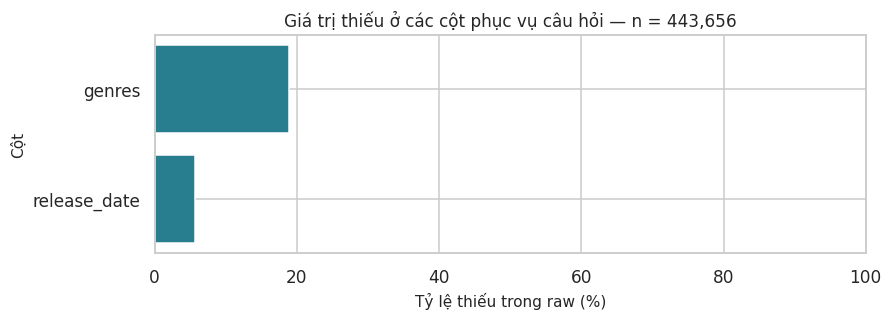

,release_date,genres,original_language,số dòng,tỷ lệ raw (%)
0,False,False,False,354549,79.92
1,False,True,False,63744,14.37
2,True,True,False,20069,4.52
3,True,False,False,5294,1.19


Đồng thời thiếu ở cột,release_date,genres,original_language
Thiếu ở cột,,,
release_date,25363,20069,0
genres,20069,83813,0
original_language,0,0,0


,số dòng,thiếu_release_date,thiếu_genres,thiếu_original_language,budget_bằng_0,revenue_bằng_0,runtime_bằng_0,TMDB_không_lượt_chấm
status,,,,,,,,
Canceled,9,88.89,33.33,0.0,88.89,100.00,66.67,100.00
In Production,1043,37.20,16.30,0.0,92.71,99.90,68.46,100.00
Planned,161,70.19,14.91,0.0,91.93,100.00,84.47,100.00
Post Production,1676,57.10,12.77,0.0,92.30,100.00,64.32,99.88
Released,440762,5.42,18.92,0.0,93.16,96.22,13.50,38.77
Rumored,5,100.00,20.00,0.0,100.00,100.00,80.00,80.00


,số dòng,thiếu_release_date,thiếu_genres,thiếu_original_language,budget_bằng_0,revenue_bằng_0,runtime_bằng_0,TMDB_không_lượt_chấm
original_language,,,,,,,,
Các ngôn ngữ còn lại,76007,2.70,11.90,0.0,95.69,97.39,17.86,40.20
de,21843,2.92,11.93,0.0,97.83,98.82,36.86,42.74
en,242967,8.07,23.41,0.0,90.76,95.42,9.10,41.87
es,21908,4.10,19.34,0.0,95.79,97.04,21.28,27.30
fr,24927,2.88,16.62,0.0,95.92,97.50,15.11,29.79
hi,6075,1.89,18.40,0.0,92.16,93.28,18.85,36.89
it,11978,3.34,13.81,0.0,96.72,97.65,22.82,27.84
ja,13285,0.78,10.52,0.0,98.07,96.50,3.20,25.98
pt,8287,3.21,13.50,0.0,96.11,98.66,21.30,42.51


,số dòng,thiếu_release_date,thiếu_genres,thiếu_original_language,budget_bằng_0,revenue_bằng_0,runtime_bằng_0,TMDB_không_lượt_chấm
release_date,,,,,,,,
1870,19,0.0,15.79,0.0,94.74,100.00,15.79,57.89
1880,33,0.0,21.21,0.0,93.94,100.00,21.21,69.70
1890,1058,0.0,33.74,0.0,100.00,100.00,2.65,8.13
1900,2035,0.0,38.67,0.0,99.66,100.00,2.21,20.84
1910,4024,0.0,21.32,0.0,99.20,99.55,10.16,36.98
1920,5638,0.0,14.19,0.0,98.19,98.81,15.68,47.87
1930,12763,0.0,9.23,0.0,97.79,99.00,9.44,38.54
1940,11897,0.0,7.81,0.0,97.81,98.44,7.14,33.81
1950,15495,0.0,10.93,0.0,97.71,98.30,12.80,33.31


Có **20,069 dòng** vừa thiếu ngày phát hành vừa thiếu thể loại, chiếm **79.13%** các dòng thiếu ngày. Ngân sách và doanh thu có tỷ lệ thiếu khi đọc lần lượt là **0.00%** và **0.00%**, nên cần đọc tiếp bảng số 0 ở mục 4 để đánh giá khả năng dùng tài chính.

In [4]:
missing_table = pd.DataFrame({
    'NA khi đọc': movies.isna().sum(),
    'chỉ khoảng trắng': space_only,
    'số thiếu': missing.sum(),
    'tỷ lệ thiếu (%)': 100 * missing.mean(),
}).sort_values('số thiếu', ascending=False)
display(missing_table.round(2))

important = ['release_date', 'genres', 'original_language', 'runtime', 'budget', 'revenue',
             'vote_average', 'vote_count', 'averageRating', 'numVotes']
display(missing_table.loc[important].round(2))
shown = missing_table.loc[important].query('`số thiếu` > 0').sort_values('tỷ lệ thiếu (%)')
fig, ax = plt.subplots(figsize=(8, 2.8), layout='constrained')
ax.barh(shown.index, shown['tỷ lệ thiếu (%)'], color='#287e8e')
ax.set(xlabel='Tỷ lệ thiếu trong raw (%)', ylabel='Cột', xlim=(0, 100),
       title=f'Giá trị thiếu ở các cột phục vụ câu hỏi — n = {n:,}')
plt.show()

pattern_columns = ['release_date', 'genres', 'original_language']
patterns = missing[pattern_columns].value_counts().rename('số dòng').reset_index()
patterns['tỷ lệ raw (%)'] = 100 * patterns['số dòng'] / n
display(patterns.round(2))
co_missing = missing[pattern_columns].astype('int64').T @ missing[pattern_columns].astype('int64')
display(co_missing.rename_axis(index='Thiếu ở cột', columns='Đồng thời thiếu ở cột'))

availability = missing[pattern_columns].rename(columns=lambda col: 'thiếu_' + col).copy()
availability['budget_bằng_0'] = movies.budget.eq(0)
availability['revenue_bằng_0'] = movies.revenue.eq(0)
availability['runtime_bằng_0'] = movies.runtime.eq(0)
availability['TMDB_không_lượt_chấm'] = movies.vote_count.eq(0)

def missing_by_group(groups):
    result = availability.groupby(groups, observed=True, dropna=False).mean().mul(100)
    result.insert(0, 'số dòng', groups.value_counts(dropna=False))
    return result.round(2)

display(missing_by_group(movies.status))
top_languages = movies.original_language.value_counts().head(10).index
language_groups = movies.original_language.where(
    movies.original_language.isin(top_languages), 'Các ngôn ngữ còn lại')
display(missing_by_group(language_groups))

release_dates = pd.to_datetime(movies.release_date, format='%Y-%m-%d', errors='coerce')
release_years = release_dates.dt.year
decades = ((release_years // 10) * 10).astype('Int64').astype('string').fillna('Thiếu/không đọc được')
display(missing_by_group(decades))

joint_missing = int((missing.release_date & missing.genres).sum())
display(Markdown(
    f'Có **{joint_missing:,} dòng** vừa thiếu ngày phát hành vừa thiếu thể loại, '
    f'chiếm **{joint_missing / missing.release_date.sum():.2%}** các dòng thiếu ngày. '
    f'Ngân sách và doanh thu có tỷ lệ thiếu khi đọc lần lượt là '
    f'**{missing.budget.mean():.2%}** và **{missing.revenue.mean():.2%}**, '
    'nên cần đọc tiếp bảng số 0 ở mục 4 để đánh giá khả năng dùng tài chính.'
))

Homepage, tagline và keywords thiếu nhiều nhưng các câu hỏi đã chốt tập trung vào đặc điểm,
điểm và tài chính. Các trường cần ưu tiên xử lý là ngày phát hành, thể loại và các số 0 chưa rõ ý nghĩa.
Mức thiếu thể loại khác nhau giữa các nhóm ngôn ngữ, vì vậy lọc theo độ đầy đủ có thể thay đổi
thành phần mẫu.

Q1 cần giữ cặp điểm và lượt chấm của cùng tác phẩm. Ngày thiếu ảnh hưởng đến phạm vi của cả bốn câu.
Q2 có thể dùng cách xử lý đầu vào thiếu học từ tập huấn luyện trong Pipeline. Q3 cần xem xét thời lượng 0,
còn Q4 cần kiểm tra tài chính 0 và cực trị. Mục 6 ghi số dòng sau từng điều kiện của mỗi câu.

## 4. Phân phối số, số 0 và cực trị

Bảng đầu giữ toàn bộ giá trị raw. Bảng thứ hai chỉ mô tả các giá trị **dương**, có báo cáo số mẫu;
đây là chẩn đoán sự lệch phân phối, chưa phải quyết định loại số 0.
Bảng so sánh cờ ngoài ngưỡng Tukey `Q1 − 1,5 × IQR`, `Q3 + 1,5 × IQR` với cờ `|z| > 3`.
Hai phương pháp dùng cùng mẫu của mỗi cột. Z-score được tính với độ lệch chuẩn `ddof=0`.
Giá trị ngoài ngưỡng chưa đủ để kết luận sai hay tự loại phim.

In [5]:
numeric_cols = ['budget', 'revenue', 'runtime', 'vote_average', 'vote_count',
                'averageRating', 'numVotes']
numeric_summary = movies[numeric_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
numeric_summary['IQR'] = numeric_summary['75%'] - numeric_summary['25%']
numeric_summary['số 0'] = movies[numeric_cols].eq(0).sum()
numeric_summary['tỷ lệ 0 (%)'] = 100 * movies[numeric_cols].eq(0).mean()
numeric_summary['số âm'] = movies[numeric_cols].lt(0).sum()
with pd.option_context('display.max_columns', None):
    display(numeric_summary.round(3))

positive_cols = ['budget', 'revenue', 'runtime', 'vote_count', 'numVotes']
positive_summary = pd.DataFrame({col: movies.loc[movies[col].gt(0), col]
    .describe(percentiles=[.01, .25, .5, .75, .99]) for col in positive_cols}).T
display(positive_summary.round(3))

outliers = []
for col in numeric_cols:
    s = movies.loc[movies[col].gt(0), col] if col in positive_cols else movies[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_flagged = s.lt(lo) | s.gt(hi)
    z_scores = (s - s.mean()) / s.std(ddof=0)
    valid_z = z_scores.notna()
    z_flagged = z_scores.abs().gt(3)
    outliers.append([
        col, '> 0' if col in positive_cols else 'không thiếu', len(s), lo, hi,
        int(iqr_flagged.sum()), 100 * iqr_flagged.mean(), int(valid_z.sum()),
        int(z_flagged.sum()), 100 * z_flagged.loc[valid_z].mean(),
    ])

outlier_audit = pd.DataFrame(outliers, columns=[
    'cột', 'mẫu', 'n', 'ngưỡng dưới IQR', 'ngưỡng trên IQR',
    'số cờ IQR', 'tỷ lệ cờ IQR (%)', 'số z hợp lệ', 'số cờ z', 'tỷ lệ cờ z (%)',
])
with pd.option_context('display.max_columns', None):
    display(outlier_audit.round(3))

positive_outliers = outlier_audit.set_index('cột').loc[positive_cols]
fewer_z_flags = positive_outliers.index[
    positive_outliers['số cờ z'].lt(positive_outliers['số cờ IQR'])].tolist()
display(Markdown(
    'Z-score dùng trung bình và độ lệch chuẩn với `ddof=0`, ngưỡng gắn cờ là `|z| > 3`. '
    f'Trên cùng mẫu giá trị dương, các cột có ít cờ z-score hơn IQR là '
    f'**{", ".join(fewer_z_flags)}**. '
    'Cột có phương sai bằng 0 sẽ có z-score chưa xác định, được thể hiện qua số z hợp lệ '
    'và tỷ lệ cờ không xác định.'
))

numeric_checks = pd.Series({
    'budget hoặc revenue âm': int((movies.budget.lt(0) | movies.revenue.lt(0)).sum()),
    'budget và revenue cùng dương': int((movies.budget.gt(0) & movies.revenue.gt(0)).sum()),
    'TMDB ngoài [0, 10]': int((~movies.vote_average.between(0, 10)).sum()),
    'IMDb ngoài [1, 10]': int((~movies.averageRating.between(1, 10)).sum()),
    'TMDB điểm 0 nhưng có lượt chấm': int((movies.vote_average.eq(0) & movies.vote_count.gt(0)).sum()),
    'TMDB điểm dương nhưng 0 lượt chấm': int((movies.vote_average.gt(0) & movies.vote_count.eq(0)).sum()),
    'runtime bằng 0': int(movies.runtime.eq(0).sum()),
    'runtime trên 600 phút (cờ kiểm tra, không loại)': int(movies.runtime.gt(600).sum()),
})
display(numeric_checks.to_frame('Số bản ghi'))
for col in ['budget', 'revenue', 'runtime']:
    display(Markdown(f'**Ví dụ cực trị `{col}`: 3 dòng lớn nhất và 3 dòng dương nhỏ nhất.**'))
    positive = movies.loc[movies[col].gt(0)]
    example_index = positive.nlargest(3, col).index.union(positive.nsmallest(3, col).index)
    display(movies.loc[example_index, ['id', 'tconst', 'title', 'release_date', col]]
            .sort_values(col, ascending=False))

,count,mean,std,min,1%,25%,50%,75%,99%,max,IQR,số 0,tỷ lệ 0 (%),số âm
budget,443656.0,643344.339,7.379826e+06,0.0,0.0,0.0,0.0,0.0,15645000.00,8.880000e+08,0.0,413295,93.157,0
revenue,443656.0,1638287.557,2.601773e+07,0.0,0.0,0.0,0.0,0.0,24146317.70,2.923706e+09,0.0,427001,96.246,0
runtime,443656.0,66.247,6.423400e+01,0.0,0.0,15.0,80.0,96.0,180.00,1.440000e+04,81.0,61425,13.845,0
vote_average,443656.0,3.551,3.160000e+00,0.0,0.0,0.0,4.5,6.2,10.00,1.000000e+01,6.2,173876,39.192,0
vote_count,443656.0,47.946,5.077530e+02,0.0,0.0,0.0,1.0,5.0,845.00,3.449500e+04,5.0,173757,39.165,0
averageRating,443656.0,6.223,1.312000e+00,1.0,2.7,5.4,6.3,7.1,9.00,1.000000e+01,1.7,0,0.000,0
numVotes,443656.0,3264.497,3.492041e+04,5.0,7.0,24.0,74.0,356.0,57555.25,3.261330e+06,332.0,0,0.000,0


,count,mean,std,min,1%,25%,50%,75%,99%,max
budget,30361.0,9.400994e+06,2.671189e+07,1.0,4.0,15000.0,500000.0,6000000.0,1.400000e+08,8.880000e+08
revenue,16655.0,4.364071e+07,1.272784e+08,1.0,10.0,343200.0,4296804.0,27683944.0,6.512521e+08,2.923706e+09
runtime,382231.0,7.689300e+01,6.301200e+01,1.0,2.0,51.0,86.0,99.0,1.820000e+02,1.440000e+04
vote_count,269899.0,7.881400e+01,6.491210e+02,1.0,1.0,2.0,4.0,12.0,1.563000e+03,3.449500e+04
numVotes,443656.0,3.264497e+03,3.492041e+04,5.0,7.0,24.0,74.0,356.0,5.755525e+04,3.261330e+06


,cột,mẫu,n,ngưỡng dưới IQR,ngưỡng trên IQR,số cờ IQR,tỷ lệ cờ IQR (%),số z hợp lệ,số cờ z,tỷ lệ cờ z (%)
0,budget,> 0,30361,-8962500.00,14977500.00,4771,15.714,30361,643,2.118
1,revenue,> 0,16655,-40667916.00,68695060.00,2419,14.524,16655,319,1.915
2,runtime,> 0,382231,-21.00,171.00,5798,1.517,382231,1196,0.313
3,vote_average,không thiếu,443656,-9.30,15.50,0,0.000,443656,0,0.000
4,vote_count,> 0,269899,-13.00,27.00,40271,14.921,269899,2135,0.791
5,averageRating,không thiếu,443656,2.85,9.65,5907,1.331,443656,1932,0.435
6,numVotes,> 0,443656,-474.00,854.00,71794,16.182,443656,2739,0.617


Z-score dùng trung bình và độ lệch chuẩn với `ddof=0`, ngưỡng gắn cờ là `|z| > 3`. Trên cùng mẫu giá trị dương, các cột có ít cờ z-score hơn IQR là **budget, revenue, runtime, vote_count, numVotes**. Cột có phương sai bằng 0 sẽ có z-score chưa xác định, được thể hiện qua số z hợp lệ và tỷ lệ cờ không xác định.

,Số bản ghi
budget hoặc revenue âm,0
budget và revenue cùng dương,10425
"TMDB ngoài [0, 10]",0
"IMDb ngoài [1, 10]",0
TMDB điểm 0 nhưng có lượt chấm,457
TMDB điểm dương nhưng 0 lượt chấm,338
runtime bằng 0,61425
"runtime trên 600 phút (cờ kiểm tra, không loại)",233


**Ví dụ cực trị `budget`: 3 dòng lớn nhất và 3 dòng dương nhỏ nhất.**

,id,tconst,title,release_date,budget
400850,1057999,tt27219440,Enea,2023-09-21,888000000
270441,1399448,tt6161168,Red Dead Redemption 2 (Movie),2024-03-21,540000000
270442,1399448,tt6161168,Red Dead Redemption 2 (Movie),2024-03-21,540000000
11073,571055,tt9061402,Down,2019-02-01,1
12213,16664,tt0297721,All About Lily Chou-Chou,2001-10-06,1
14900,20034,tt1093369,Hush,2008-08-13,1


**Ví dụ cực trị `revenue`: 3 dòng lớn nhất và 3 dòng dương nhỏ nhất.**

,id,tconst,title,release_date,revenue
3,19995,tt0499549,Avatar,2009-12-15,2923706026
15,299534,tt4154796,Avengers: Endgame,2019-04-24,2800000000
281,76600,tt1630029,Avatar: The Way of Water,2022-12-14,2320250281
10094,14424,tt0497972,Sex and Death 101,2007-06-15,1
21385,500735,tt7823036,Finally Married,2018-01-25,1
21878,32834,tt0196106,MVP: Most Valuable Primate,2000-08-11,1


**Ví dụ cực trị `runtime`: 3 dòng lớn nhất và 3 dòng dương nhỏ nhất.**

,id,tconst,title,release_date,runtime
197760,251800,tt2659636,Modern Times Forever,2011-03-23,14400
334721,710874,tt11707418,Svalbard minutt for minutt,2020-01-31,13319
102153,272074,tt0242365,Cinématon,1978-12-20,12480
7162,160,tt0000012,The Arrival of a Train at La Ciotat,1897-10-10,1
9018,774,tt0000010,Workers Leaving the Lumière Factory,1895-03-22,1
10846,82120,tt0000014,The Sprinkler Sprinkled,1895-06-10,1


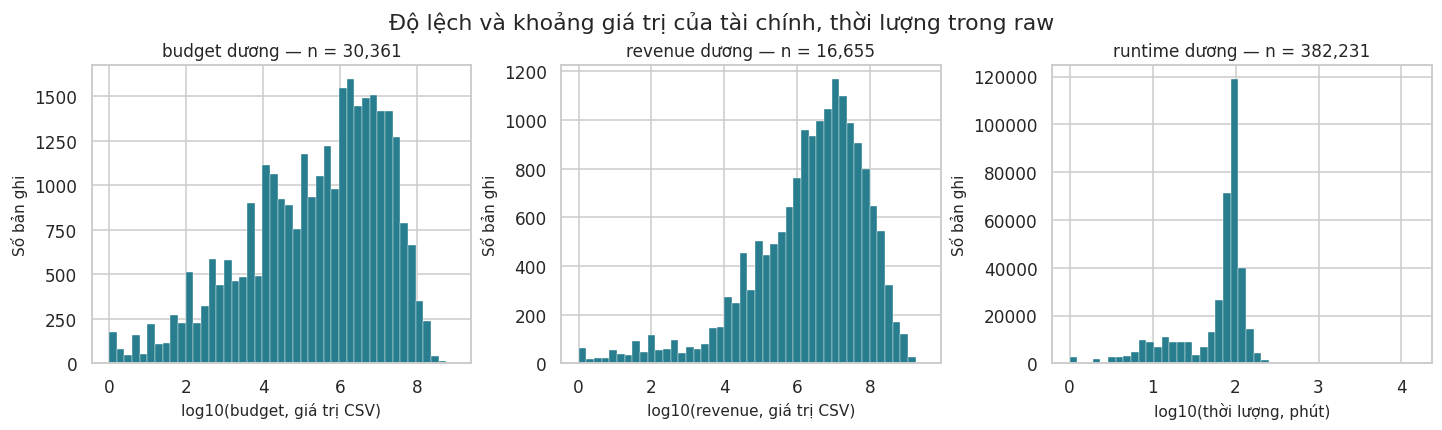

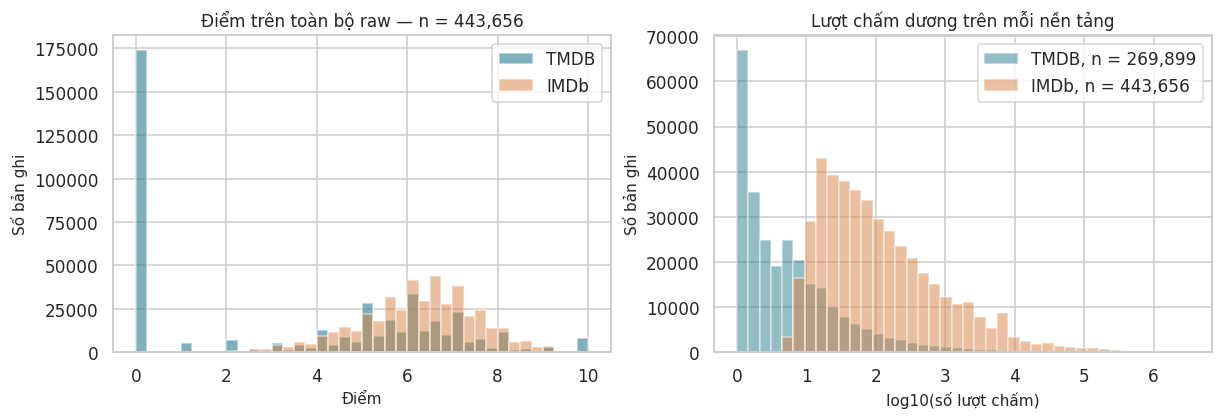

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
for ax, col in zip(axes, ['budget', 'revenue', 'runtime']):
    values = movies.loc[movies[col].gt(0), col]
    ax.hist(np.log10(values), bins=45, color='#287e8e', edgecolor='white', linewidth=.25)
    ax.set(title=f'{col} dương — n = {len(values):,}',
           xlabel=f'log10({col}, giá trị CSV)' if col != 'runtime' else 'log10(thời lượng, phút)',
           ylabel='Số bản ghi')
fig.suptitle('Độ lệch và khoảng giá trị của tài chính, thời lượng trong raw')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout='constrained')
axes[0].hist(movies.vote_average, bins=np.linspace(0, 10, 41), alpha=.6, label='TMDB', color='#287e8e')
axes[0].hist(movies.averageRating, bins=np.linspace(0, 10, 41), alpha=.5, label='IMDb', color='#d98243')
axes[0].set(title=f'Điểm trên toàn bộ raw — n = {n:,}', xlabel='Điểm', ylabel='Số bản ghi')
axes[0].legend()
vote_bins = np.linspace(0, np.log10(movies[['vote_count', 'numVotes']].max().max()), 41)
for col, label, color in [('vote_count', 'TMDB', '#287e8e'), ('numVotes', 'IMDb', '#d98243')]:
    values = movies.loc[movies[col].gt(0), col]
    axes[1].hist(np.log10(values), bins=vote_bins, alpha=.5, color=color,
                 label=f'{label}, n = {len(values):,}')
axes[1].set(title='Lượt chấm dương trên mỗi nền tảng', xlabel='log10(số lượt chấm)', ylabel='Số bản ghi')
axes[1].legend()
plt.show()

Ngân sách và doanh thu bằng 0 ở phần lớn raw, làm trung vị và tứ phân vị 75% đều bằng 0.
Trên các giá trị dương, trung bình lớn hơn nhiều so với trung vị và khoảng giá trị rất rộng.
Biểu đồ dùng log10 để quan sát phân phối. Ví dụ, 1.000 và 1.000.000 được đưa về 3 và 6.
Số 0 được đếm ở bảng riêng vì log10 chỉ áp dụng cho giá trị dương.

Thời lượng 0, tài chính rất nhỏ và các tác phẩm dài hàng nghìn phút là những trường hợp cần đối chiếu.
Bảng IQR gắn cờ các giá trị khác biệt so với phần giữa của phân phối. Cờ này hỗ trợ tìm ví dụ để kiểm tra.
Q3 cần quyết định phạm vi tác phẩm sau khi xem cả phân phối và những ví dụ cực trị.
Q1 cần kiểm tra các trường hợp điểm và lượt chấm chưa nhất quán trước khi chọn ngưỡng.

Các biến tài chính và lượt chấm có phân phối lệch phải mạnh. Trung bình và độ lệch chuẩn dùng
trong z-score chịu ảnh hưởng của các giá trị cực đại, nên z-score có thể gắn ít cờ hơn IQR.
Bảng trên cho phép kiểm tra điều này trên từng cột của CSV. IQR cung cấp góc nhìn dựa trên phần
50% giữa của phân phối, còn log-transform giúp nhìn rõ khoảng giá trị rộng và đuôi phân phối.
Việc xác định một giá trị là lỗi hay là trường hợp thực tế cần được đối chiếu thêm với nguồn.

Đã đối chiếu mô tả của [bản ghép](https://www.kaggle.com/datasets/ggtejas/tmdb-imdb-merged-movies-dataset)
và [nguồn TMDB](https://www.kaggle.com/datasets/asaniczka/tmdb-movies-dataset-2023-930k-movies)
ngày 17/11/2026. Các mô tả được đọc chưa cung cấp đủ bằng chứng về đơn vị tiền tệ, phạm vi doanh thu
và cách chuẩn hóa của CSV v578. Những bảng tài chính trong notebook ghi nhãn **giá trị CSV**.
So sánh doanh thu có ý nghĩa tiền tệ ở Q4 cần xác minh thêm các thông tin này, cùng cách xử lý khác biệt
thời gian và lạm phát. Notebook hiện kiểm tra phân phối và khả năng tạo nhóm của mẫu có tài chính dương.

## 5. Biến phân loại, đa nhãn và ngày

Đếm nhóm hiếm ở mức **tối đa 5 bản ghi** chỉ để chẩn đoán, chưa gom vào “khác” cho phân tích.
Kiểm tra nhãn sau `strip()` và `casefold()` để tìm các cách viết có thể trùng nghĩa.
Không tự gộp nhãn nếu chưa xác minh ý nghĩa.

In [7]:
category_audit = []
for col in ['original_language', 'status']:
    counts = movies.loc[~missing[col], col].value_counts()
    category_audit.append([col, len(counts), int(counts.le(5).sum()), int(counts[counts.le(5)].sum()),
                           int(missing[col].sum())])
    display(Markdown(f'**`{col}`: nhóm phổ biến (tối đa 15).**'))
    display(pd.DataFrame({'số bản ghi': counts.head(15), 'tỷ lệ raw (%)': counts.head(15) * 100 / n}).round(2))
display(pd.DataFrame(category_audit, columns=['cột', 'số nhãn', 'nhãn có ≤5 dòng',
                                             'dòng thuộc nhãn hiếm', 'số thiếu']))
label_checks = []
for col in ['original_language', 'status']:
    values = movies.loc[~missing[col], col]
    pairs = pd.DataFrame({'raw': values, 'normalized': values.str.strip().str.casefold()}).drop_duplicates()
    collisions = pairs.groupby('normalized').raw.nunique()
    label_checks.append([col, int(values.ne(values.str.strip()).sum()), int(collisions.gt(1).sum())])
    rare = values.value_counts()
    display(rare[rare.le(5)].head(20).to_frame(f'{col}: ví dụ nhãn hiếm'))
display(pd.DataFrame(label_checks, columns=['cột', 'dòng có khoảng trắng thừa', 'nhãn chuẩn hóa có nhiều cách viết']))
display(pd.Series({'original_language không phải 2 chữ cái thường':
    int((~movies.original_language.str.fullmatch(r'[a-z]{2}', na=False)).sum())}))

**`original_language`: nhóm phổ biến (tối đa 15).**

,số bản ghi,tỷ lệ raw (%)
original_language,,
en,242967,54.76
fr,24927,5.62
es,21908,4.94
de,21843,4.92
ja,13285,2.99
it,11978,2.70
ru,9472,2.13
pt,8287,1.87
zh,6907,1.56


**`status`: nhóm phổ biến (tối đa 15).**

,số bản ghi,tỷ lệ raw (%)
status,,
Released,440762,99.35
Post Production,1676,0.38
In Production,1043,0.24
Planned,161,0.04
Canceled,9,0.00
Rumored,5,0.00


,cột,số nhãn,nhãn có ≤5 dòng,dòng thuộc nhãn hiếm,số thiếu
0,original_language,158,38,79,0
1,status,6,1,5,0


,original_language: ví dụ nhãn hiếm
original_language,
fy,5
cr,4
ce,4
sm,4
tt,4
gn,4
lg,3
ny,3
ti,3


,status: ví dụ nhãn hiếm
status,
Rumored,5


,cột,dòng có khoảng trắng thừa,nhãn chuẩn hóa có nhiều cách viết
0,original_language,0,0
1,status,0,0


original_language không phải 2 chữ cái thường    0
dtype: int64

In [8]:
display(movies.loc[~missing.genres, 'genres'].head(10).to_frame('Ví dụ chuỗi genres raw'))
# Chỉ áp dụng parser này cho genres: dữ liệu thực dùng tên thể loại phân cách bằng dấu phẩy.
genre_lists = movies.genres.fillna('').str.split(',').map(lambda parts: [p.strip() for p in parts if p.strip()])
genre_count = genre_lists.map(len)
genre_duplicate_tokens = genre_lists.map(lambda parts: len(parts) != len(set(parts)))
genre_brackets = movies.genres.fillna('').str.contains(r'[\[\]{}]', regex=True)
display(pd.Series({'dòng thiếu genres': int(missing.genres.sum()),
    'dòng có nhiều thể loại': int(genre_count.gt(1).sum()),
    'dòng lặp nhãn trong cùng genres': int(genre_duplicate_tokens.sum()),
    'dòng chứa dấu ngoặc cần parser khác': int(genre_brackets.sum()),
    'số thể loại tối đa trên một dòng': int(genre_count.max())}))
genre_tokens = genre_lists.map(lambda parts: sorted(set(parts))).explode().dropna()
genre_counts = genre_tokens.value_counts()
display(pd.DataFrame({'số bản ghi chứa thể loại': genre_counts,
                      'tỷ lệ trong raw (%)': 100 * genre_counts / n}).round(2))
display(genre_count.value_counts().sort_index().to_frame('Số bản ghi theo số nhãn genres'))

invalid_dates = ~missing.release_date & release_dates.isna()
non_iso = ~missing.release_date & ~movies.release_date.str.fullmatch(r'\d{4}-\d{2}-\d{2}', na=False)
date_audit = pd.Series({'thiếu release_date': int(missing.release_date.sum()),
    'có giá trị nhưng không parse được': int(invalid_dates.sum()),
    'chuỗi không đúng YYYY-MM-DD': int(non_iso.sum()),
    'ngày sớm nhất': str(release_dates.min().date()),
    'ngày muộn nhất': str(release_dates.max().date()),
    'sau ngày nhóm tải 05/11/2026': int(release_dates.gt(DOWNLOAD_DATE).sum()),
    'Released nhưng ngày sau ngày tải': int((release_dates.gt(DOWNLOAD_DATE) & movies.status.eq('Released')).sum())})
display(date_audit.to_frame('Kết quả'))
display(movies.loc[invalid_dates | non_iso | release_dates.gt(DOWNLOAD_DATE),
                   ['id', 'tconst', 'title', 'release_date', 'status']].head(15))

,Ví dụ chuỗi genres raw
0,"Action, Science Fiction, Adventure"
1,"Adventure, Drama, Science Fiction"
2,"Drama, Action, Crime, Thriller"
3,"Action, Adventure, Fantasy, Science Fiction"
4,"Science Fiction, Action, Adventure"
5,"Action, Adventure, Comedy"
6,"Adventure, Action, Science Fiction"
7,Drama
8,"Action, Science Fiction, Adventure"
9,"Thriller, Crime"


dòng thiếu genres                       83813
dòng có nhiều thể loại                 171236
dòng lặp nhãn trong cùng genres            95
dòng chứa dấu ngoặc cần parser khác         0
số thể loại tối đa trên một dòng           11
dtype: int64

,số bản ghi chứa thể loại,tỷ lệ trong raw (%)
genres,,
Drama,140009,31.56
Comedy,92583,20.87
Documentary,59518,13.42
Romance,35904,8.09
Thriller,33768,7.61
Action,32986,7.44
Horror,31615,7.13
Animation,26322,5.93
Crime,25105,5.66


,Số bản ghi theo số nhãn genres
genres,
0,83813
1,188607
2,108518
3,47958
4,11443
5,2570
6,628
7,95
8,18


,Kết quả
thiếu release_date,25363
có giá trị nhưng không parse được,0
chuỗi không đúng YYYY-MM-DD,0
ngày sớm nhất,1874-12-09
ngày muộn nhất,2029-10-13
sau ngày nhóm tải 05/11/2026,3
Released nhưng ngày sau ngày tải,2


,id,tconst,title,release_date,status
272007,1225835,tt8270746,শূন্যতা,2027-04-21,Released
286448,1355413,tt5835938,Pela Adhi Akshar,2027-03-24,In Production
287509,1227249,tt10333734,Indiana Jones: Return of Elsa Schneider,2029-10-13,Released


Ngôn ngữ gốc và trạng thái có phân bố mất cân bằng, nên cần ghi số mẫu khi xem các nhóm nhỏ.
Ngưỡng tối đa 5 dòng trong bảng nhãn hiếm giúp tìm những nhóm có ít quan sát. Ranh giới gom nhóm
cho phân tích hoặc ML sẽ được chọn theo mẫu của câu hỏi và độ đầy đủ thực tế.

Một tác phẩm có nhiều thể loại. Code loại nhãn lặp trong mỗi danh sách trước khi đếm, và mỗi tác phẩm
có thể xuất hiện ở nhiều nhóm. Tổng tỷ lệ thể loại do đó có thể vượt 100%. Khi so sánh tài chính,
cần giữ định danh tác phẩm và xác định cách phân bổ trước khi tính tổng qua các thể loại.

Ngày có giá trị đều đọc được trên bản CSV hiện tại, nhưng vẫn có ngày sau ngày nhóm tải và trạng thái
cần đối chiếu. Mốc 1990–2024 phục vụ Q1, Q3, Q4. Q2 có phần trước 2020 và phần 2020–2024 theo
phương án chia thời gian đã ghi trong `QUESTIONS.md`. Các bảng tiếp theo kiểm tra độ phủ của những phạm vi này.

In [9]:
period_labels = ['1990–1999', '2000–2009', '2010–2019', '2020–2024']
raw_periods = pd.cut(release_years, bins=[1989, 1999, 2009, 2019, 2024], labels=period_labels)
coverage_1990_2024 = pd.DataFrame({
    'bản ghi raw': raw_periods.value_counts(sort=False),
    'bản ghi có hai mã duy nhất': raw_periods.loc[unique_keys].value_counts(sort=False),
})
display(coverage_1990_2024)
display(pd.Series({
    'thiếu hoặc không đọc được ngày': int(release_dates.isna().sum()),
    'trước 1990': int(release_years.lt(1990).sum()),
    '1990–2024': int(release_years.between(1990, 2024).sum()),
    'sau 2024': int(release_years.gt(2024).sum()),
}, name='Độ phủ ngày phát hành trên raw'))

genre_quality = availability[['thiếu_release_date', 'budget_bằng_0', 'revenue_bằng_0', 'runtime_bằng_0']].copy()
genre_quality['genre'] = genre_lists.map(lambda labels: sorted(set(labels)))
genre_quality = genre_quality.explode('genre').dropna(subset=['genre'])
genre_availability = genre_quality.groupby('genre').mean().mul(100)
genre_availability.insert(0, 'số bản ghi', genre_quality.groupby('genre').size())
display(genre_availability.sort_values('số bản ghi', ascending=False).head(10).round(2))

,bản ghi raw,bản ghi có hai mã duy nhất
release_date,,
1990–1999,39120,38788
2000–2009,69832,68860
2010–2019,123528,121025
2020–2024,50388,45267


thiếu hoặc không đọc được ngày     25363
trước 1990                        135411
1990–2024                         282868
sau 2024                              14
Name: Độ phủ ngày phát hành trên raw, dtype: int64

,số bản ghi,thiếu_release_date,budget_bằng_0,revenue_bằng_0,runtime_bằng_0
genre,,,,,
Drama,140009,1.08,91.82,94.53,9.78
Comedy,92583,1.49,91.36,93.85,12.06
Documentary,59518,1.68,96.35,98.96,8.25
Romance,35904,0.98,90.60,91.75,8.71
Thriller,33768,1.99,83.46,89.98,7.30
Action,32986,2.34,85.57,89.75,10.17
Horror,31615,2.92,83.14,94.10,6.39
Animation,26322,1.31,95.62,95.75,5.07
Crime,25105,1.23,88.56,91.58,9.21


Bảng thiếu và số 0 theo thể loại sử dụng các bản ghi raw có nhãn thể loại. Một tác phẩm có thể
góp mặt ở nhiều hàng. Các tỷ lệ cho biết khả năng có dữ liệu phục vụ Q3 và Q4 trong từng nhóm.
Giai đoạn 2020–2024 dài 5 năm, còn ba giai đoạn trước dài 10 năm. Số mẫu ở đây thể hiện độ phủ
của dataset trong mỗi khoảng thời gian.

## 6. Mẫu theo câu hỏi và các mối liên hệ sơ bộ

Điểm bắt đầu là các dòng có cả `id` và `tconst` xuất hiện đúng một lần trong raw, theo lựa chọn mẫu A
đã ghi nhận ngày 15/11/2026. Mỗi nhóm mã lặp bị loại toàn bộ khỏi mẫu này. Một số nhóm chỉ khác
danh sách diễn viên cũng bị loại, nên cần xem ảnh hưởng của lựa chọn này đến thành phần tác phẩm.

Q1 dùng phạm vi 1990–2024, điểm trong miền và lượt chấm ở cả hai nền tảng. Ngưỡng 10 là mẫu
khảo sát chính, bảng sau đối chiếu thêm ngưỡng 100 theo câu hỏi. Q2 giữ đầu vào thiếu để kiểm tra
khả năng xử lý trong Pipeline và tách hai khoảng thời gian. Q3, Q4 dùng trạng thái `Released`
và các điều kiện riêng đã nêu trong `QUESTIONS.md`.

Các bảng mô tả và biểu đồ dưới đây chuẩn bị cho phân tích có kiểm soát ở notebook 02
và quy trình mô hình ở notebook 03.

In [10]:
analysis_base = movies.loc[unique_keys, focus_columns + ['title']].copy()
analysis_base['release_year'] = release_years.loc[analysis_base.index]
analysis_base['period'] = raw_periods.loc[analysis_base.index]
analysis_base['genre_list'] = genre_lists.loc[analysis_base.index].map(lambda labels: sorted(set(labels)))

has_genre = genre_lists.map(len).gt(0)
year_1990_2024 = release_years.between(1990, 2024)
released = movies.status.eq('Released')
valid_imdb = movies.averageRating.between(1, 10) & movies.numVotes.gt(0)
valid_pair = (movies.vote_average.between(0, 10) & valid_imdb
              & movies.vote_count.gt(0))
question_steps = {
    'Q1': [('Năm 1990–2024', year_1990_2024),
           ('Cặp điểm trong miền và có lượt chấm', valid_pair),
           ('Cả hai nền tảng có ít nhất 10 lượt', movies.vote_count.ge(10) & movies.numVotes.ge(10))],
    'Q2': [('Có năm phát hành và năm ≤ 2024', release_years.notna() & release_years.le(2024)),
           ('Có mục tiêu IMDb trong miền và có lượt', valid_imdb)],
    'Q3': [('Trạng thái Released', released), ('Năm 1990–2024', year_1990_2024),
           ('Thời lượng dương', movies.runtime.gt(0)), ('Có thể loại', has_genre)],
    'Q4': [('Trạng thái Released', released), ('Năm 1990–2024', year_1990_2024),
           ('Ngân sách dương', movies.budget.gt(0)), ('Doanh thu dương', movies.revenue.gt(0)),
           ('Có thể loại', has_genre)],
}
flow_rows = [['Chung', 'Raw', n, 0],
             ['Chung', 'Cả hai mã xuất hiện đúng một lần', len(analysis_base), n - len(analysis_base)]]
question_masks = {}
for question, steps in question_steps.items():
    selected = unique_keys.copy()
    for label, condition in steps:
        before = int(selected.sum())
        selected &= condition
        after = int(selected.sum())
        flow_rows.append([question, label, after, before - after])
    question_masks[question] = selected

sample_flow = pd.DataFrame(flow_rows, columns=['câu', 'điều kiện thêm vào', 'số dòng còn lại', 'loại ở bước này'])
sample_flow['giữ so với raw (%)'] = 100 * sample_flow['số dòng còn lại'] / n
display(sample_flow.round(2))
question_frames = {question: analysis_base.loc[mask.loc[analysis_base.index]].copy()
                   for question, mask in question_masks.items()}
question_sizes = pd.Series({question: len(frame) for question, frame in question_frames.items()}, name='Mẫu sơ bộ')
display(question_sizes.to_frame())

profiles = pd.DataFrame({label: {
    'số dòng': len(frame),
    'ngôn ngữ gốc en (%)': 100 * frame.original_language.eq('en').mean(),
    'thiếu thể loại (%)': 100 * missing.loc[frame.index, 'genres'].mean(),
    'thời lượng 0 (%)': 100 * frame.runtime.eq(0).mean(),
    'status Released (%)': 100 * frame.status.eq('Released').mean(),
} for label, frame in [('Raw', movies), ('Hai mã duy nhất', analysis_base), *question_frames.items()]})
display(profiles.round(2))

,câu,điều kiện thêm vào,số dòng còn lại,loại ở bước này,giữ so với raw (%)
0,Chung,Raw,443656,0,100.00
1,Chung,Cả hai mã xuất hiện đúng một lần,425189,18467,95.84
2,Q1,Năm 1990–2024,273940,151249,61.75
3,Q1,Cặp điểm trong miền và có lượt chấm,179208,94732,40.39
4,Q1,Cả hai nền tảng có ít nhất 10 lượt,55418,123790,12.49
5,Q2,Có năm phát hành và năm ≤ 2024,408635,16554,92.11
6,Q2,Có mục tiêu IMDb trong miền và có lượt,408635,0,92.11
7,Q3,Trạng thái Released,422385,2804,95.21
8,Q3,Năm 1990–2024,272584,149801,61.44
9,Q3,Thời lượng dương,242634,29950,54.69


,Mẫu sơ bộ
Q1,55418
Q2,408635
Q3,209322
Q4,8049


,Raw,Hai mã duy nhất,Q1,Q2,Q3,Q4
số dòng,443656.00,425189.00,55418.00,408635.00,209322.00,8049.00
ngôn ngữ gốc en (%),54.76,53.58,56.49,52.66,55.07,72.68
thiếu thể loại (%),18.89,17.46,0.67,15.15,0.00,0.00
thời lượng 0 (%),13.85,12.97,1.55,11.64,0.00,0.87
status Released (%),99.35,99.34,100.00,99.67,100.00,100.00


In [11]:
display(Markdown(
    f'Bước định danh giữ **{len(analysis_base):,}/{n:,} dòng**. '
    f'Các mẫu sơ bộ Q1–Q4 lần lượt có **{question_sizes["Q1"]:,} / '
    f'{question_sizes["Q2"]:,} / {question_sizes["Q3"]:,} / {question_sizes["Q4"]:,} dòng**. '
    'Mẫu Q2 còn giữ đầu vào thiếu. Mẫu Q1 dùng ngưỡng 10 lượt và còn có thể thiếu thể loại, '
    'nên khi phân tích theo thể loại cần kiểm tra thêm số dòng có nhãn. '
    'Các bảng thành phần giúp đánh giá sự thay đổi của mẫu do điều kiện lọc.'
))

Bước định danh giữ **425,189/443,656 dòng**. Các mẫu sơ bộ Q1–Q4 lần lượt có **55,418 / 408,635 / 209,322 / 8,049 dòng**. Mẫu Q2 còn giữ đầu vào thiếu. Mẫu Q1 dùng ngưỡng 10 lượt và còn có thể thiếu thể loại, nên khi phân tích theo thể loại cần kiểm tra thêm số dòng có nhãn. Các bảng thành phần giúp đánh giá sự thay đổi của mẫu do điều kiện lọc.

### Tương quan tổng quan trên mẫu tài chính

Ma trận Spearman gồm tám cột số, trong đó `popularity` được dùng để xem quan hệ tổng quan.
Q2 sử dụng các biến đầu vào hồ sơ đã liệt kê ở đầu notebook. Mẫu bắt đầu từ Q4, có mã duy nhất, trạng thái
`Released`, năm 1990–2024, ngân sách và doanh thu dương, có thể loại. Sau đó lấy thời lượng dương,
điểm trong miền, lượt chấm dương ở cả hai nền tảng và giá trị hữu hạn ở đủ tám cột.
Bảng lọc ghi số tác phẩm còn lại sau mỗi bước. Mọi cặp hệ số trong hình dùng cùng mẫu hoàn chỉnh.

Spearman mô tả mức liên hệ đơn điệu theo thứ hạng, thích hợp để xem sơ bộ các biến có khoảng giá trị
rộng. Các hệ số được diễn giải trong phạm vi mẫu có thông tin tài chính và đủ các trường vừa nêu.
Các giới hạn về tiền tệ, độ đầy đủ và thành phần mẫu Q4 vẫn cần được tính đến khi phân tích tiếp.

,điều kiện thêm vào,số tác phẩm,loại thêm
0,Mẫu Q4,8049,0
1,Thời lượng dương,7979,70
2,"Điểm trong miền, cả hai nền tảng có lượt chấm",7779,200
3,Đủ tám giá trị hữu hạn,7779,0


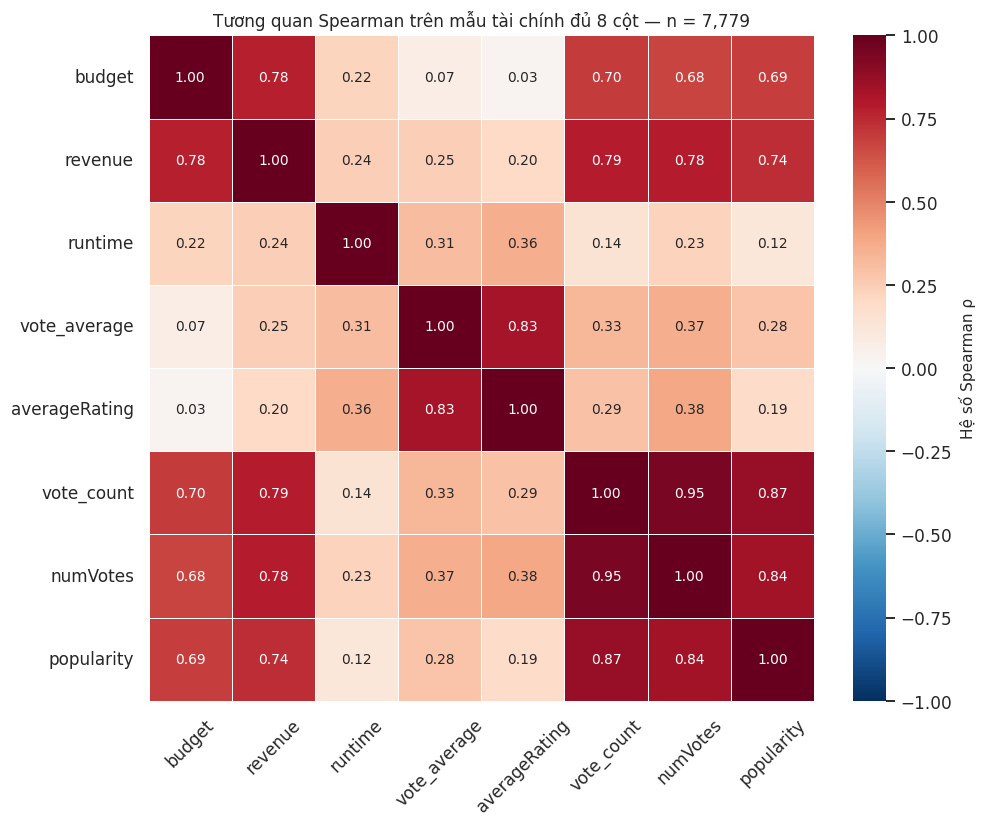

Heatmap dùng **7,779 tác phẩm**, tương đương **1.75% raw**. Spearman của ngân sách–doanh thu là **0.775**, của lượt chấm TMDB–IMDb là **0.953** trong mẫu này. Các hệ số thuộc cùng một mẫu đã lọc. Những bảng theo từng câu hỏi bên dưới có thể dùng mẫu khác theo điều kiện riêng.

In [12]:
corr_cols = ['budget', 'revenue', 'runtime', 'vote_average', 'averageRating',
             'vote_count', 'numVotes', 'popularity']
corr_index = question_frames['Q4'].index
corr_candidates = movies.loc[corr_index, corr_cols]
corr_selected = pd.Series(True, index=corr_index)
corr_steps = [
    ('Thời lượng dương', corr_candidates.runtime.gt(0)),
    ('Điểm trong miền, cả hai nền tảng có lượt chấm',
     corr_candidates.vote_average.between(0, 10)
     & corr_candidates.averageRating.between(1, 10)
     & corr_candidates.vote_count.gt(0) & corr_candidates.numVotes.gt(0)),
    ('Đủ tám giá trị hữu hạn', np.isfinite(corr_candidates).all(axis=1)),
]
corr_flow_rows = [['Mẫu Q4', len(corr_index), 0]]
for label, condition in corr_steps:
    before = int(corr_selected.sum())
    corr_selected &= condition
    after = int(corr_selected.sum())
    corr_flow_rows.append([label, after, before - after])
corr_flow = pd.DataFrame(corr_flow_rows, columns=['điều kiện thêm vào', 'số tác phẩm', 'loại thêm'])
display(corr_flow)

correlation_sample = corr_candidates.loc[corr_selected]
corr_matrix = correlation_sample.corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7.4), layout='constrained')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, center=0, square=True, linewidths=.4,
            ax=ax, cbar_kws={'label': 'Hệ số Spearman ρ'}, annot_kws={'fontsize': 9})
ax.set(title=f'Tương quan Spearman trên mẫu tài chính đủ 8 cột — n = {len(correlation_sample):,}')
ax.tick_params(axis='x', labelrotation=45)
ax.tick_params(axis='y', labelrotation=0)
plt.show()
display(Markdown(
    f'Heatmap dùng **{len(correlation_sample):,} tác phẩm**, '
    f'tương đương **{len(correlation_sample)/n:.2%} raw**. '
    f'Spearman của ngân sách–doanh thu là **{corr_matrix.loc["budget", "revenue"]:.3f}**, '
    f'của lượt chấm TMDB–IMDb là **{corr_matrix.loc["vote_count", "numVotes"]:.3f}** '
    'trong mẫu này. Các hệ số thuộc cùng một mẫu đã lọc. '
    'Những bảng theo từng câu hỏi bên dưới có thể dùng mẫu khác theo điều kiện riêng.'
))

### 6.1. Q1 — Cặp điểm và độ phủ theo lượt chấm

Từ mẫu mã duy nhất, lấy năm phát hành 1990–2024 và các cặp điểm trong miền có lượt chấm ở cả hai
nền tảng. Báo cáo số mẫu ở ngưỡng 10 và 100, cùng phần có thể loại. Các mẫu ngưỡng được lấy từ
cùng một tập cặp điểm. Chênh lệch được tính theo `TMDB − IMDb` để đọc dấu trong các bảng mô tả.

,n,có thể loại,giữ so với cặp có lượt (%),Δ trung bình,Δ trung vị,|Δ| trung bình,Spearman,TMDB điểm 0 có lượt
lượt tối thiểu ở cả hai,,,,,,,,
1,179208,161782,100.0000,-0.2261,-0.144,1.1861,0.4992,331
10,55418,55044,30.9238,0.0943,0.000,0.5613,0.7688,0
100,14559,14558,8.1241,0.1716,0.030,0.3978,0.8440,0


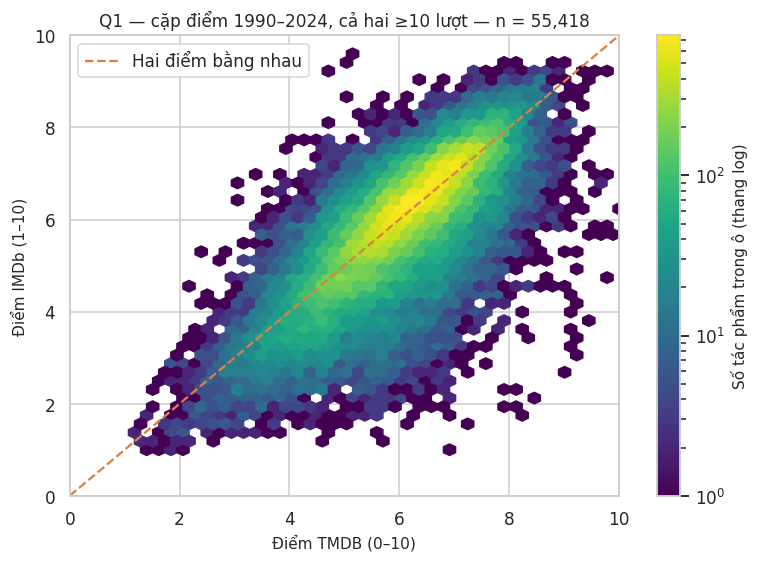

Ngưỡng 10 giữ **55,418 cặp**, còn ngưỡng 100 giữ **14,559 cặp**. Chênh lệch trung bình TMDB−IMDb lần lượt là **+0.094** và **+0.172 điểm**. Độ phủ thể loại và số mẫu thay đổi cùng ngưỡng lượt chấm. Q1 sẽ cần xem chênh lệch theo thể loại, khoảng tin cậy và độ nhạy của kết quả trong notebook 02.

In [13]:
paired_ratings = analysis_base.loc[(year_1990_2024 & valid_pair).loc[analysis_base.index]].copy()
paired_ratings['rating_gap'] = paired_ratings.vote_average - paired_ratings.averageRating
rating_rows = []
for threshold in [1, 10, 100]:
    subset = paired_ratings.loc[paired_ratings.vote_count.ge(threshold) & paired_ratings.numVotes.ge(threshold)]
    rating_rows.append({
        'lượt tối thiểu ở cả hai': threshold,
        'n': len(subset),
        'có thể loại': int(subset.genre_list.map(len).gt(0).sum()),
        'giữ so với cặp có lượt (%)': 100 * len(subset) / len(paired_ratings),
        'Δ trung bình': subset.rating_gap.mean(),
        'Δ trung vị': subset.rating_gap.median(),
        '|Δ| trung bình': subset.rating_gap.abs().mean(),
        'Spearman': subset.vote_average.corr(subset.averageRating, method='spearman'),
        'TMDB điểm 0 có lượt': int(subset.vote_average.eq(0).sum()),
    })
rating_sensitivity = pd.DataFrame(rating_rows).set_index('lượt tối thiểu ở cả hai')
with pd.option_context('display.max_columns', None):
    display(rating_sensitivity.round(4))

q1 = question_frames['Q1']
fig, ax = plt.subplots(figsize=(6.8, 5), layout='constrained')
hb = ax.hexbin(q1.vote_average, q1.averageRating, gridsize=40, mincnt=1, bins='log', cmap='viridis')
ax.plot([0, 10], [0, 10], '--', color='#d98243', label='Hai điểm bằng nhau')
ax.set(title=f'Q1 — cặp điểm 1990–2024, cả hai ≥10 lượt — n = {len(q1):,}',
       xlabel='Điểm TMDB (0–10)', ylabel='Điểm IMDb (1–10)', xlim=(0, 10), ylim=(0, 10))
ax.legend(loc='upper left')
fig.colorbar(hb, ax=ax, label='Số tác phẩm trong ô (thang log)')
plt.show()
display(Markdown(
    f'Ngưỡng 10 giữ **{int(rating_sensitivity.loc[10, "n"]):,} cặp**, '
    f'còn ngưỡng 100 giữ **{int(rating_sensitivity.loc[100, "n"]):,} cặp**. '
    f'Chênh lệch trung bình TMDB−IMDb lần lượt là '
    f'**{rating_sensitivity.loc[10, "Δ trung bình"]:+.3f}** và '
    f'**{rating_sensitivity.loc[100, "Δ trung bình"]:+.3f} điểm**. '
    'Độ phủ thể loại và số mẫu thay đổi cùng ngưỡng lượt chấm. '
    'Q1 sẽ cần xem chênh lệch theo thể loại, khoảng tin cậy và độ nhạy của kết quả trong notebook 02.'
))

### 6.2. Q2 — Đầu vào và hai khoảng thời gian

Phạm vi Q2 gồm các tác phẩm có năm phát hành đến 2024 và mục tiêu IMDb trong miền có lượt chấm.
Phần trước 2020 dùng để khám phá quan hệ giữa hồ sơ và điểm. Bảng kiểm tra phần 2020–2024
ghi số mẫu, năm và độ đầy đủ của đầu vào để chuẩn bị cách chia tập. Thể loại, thời lượng và
ngôn ngữ thiếu sẽ cần cách xử lý trong Pipeline được học từ tập huấn luyện.

,số tác phẩm,năm sớm nhất,năm muộn nhất,thiếu thể loại (%),thiếu ngôn ngữ (%),thời lượng 0 (%)
Trước 2020,363368.0,1874.0,2019.0,15.85,0.0,11.60
2020–2024,45267.0,2020.0,2024.0,9.56,0.0,11.92


,Điểm IMDb trước 2020
count,363368.000000
mean,6.203396
std,1.262128
min,1.000000
25%,5.500000
50%,6.300000
75%,7.100000
max,10.000000


,Số tác phẩm trước 2020
original_language,
en,191954
fr,21307
de,19360
es,18430
ja,11968
it,10459
ru,8494
pt,6729
zh,5559


nhãn ngôn ngữ chỉ xuất hiện ở phần 2020–2024     8
số tác phẩm có những nhãn này                   12
dtype: int64

,mẫu hiển thị,số tác phẩm,loại thêm
0,Trước 2020,363368,0
1,Có thời lượng dương để vẽ quan hệ,321212,42156


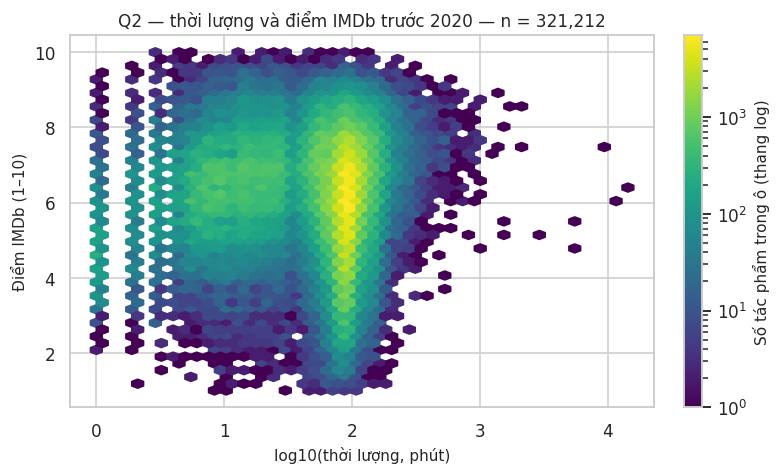

,n,diem_trung_vi
genre_list,,
Drama,121653,6.3
Comedy,79162,6.1
Documentary,48481,7.1
Romance,31550,6.2
Thriller,26506,5.7
Action,26431,5.8
Horror,23859,5.2
Animation,22461,6.5


Q2 có **363,368 tác phẩm trước 2020** và **45,267 tác phẩm 2020–2024**. Biểu đồ và bảng điểm theo thể loại sử dụng phần trước 2020. Thời lượng 0 được báo cáo riêng. Phạm vi của hình chỉ gồm thời lượng dương. Các quan hệ sơ bộ giúp kiểm tra độ phân tán và sự khác nhau giữa nhóm. Khả năng dự đoán sẽ được đánh giá bằng baseline và các mô hình trong notebook 03.

In [14]:
ml_scope = question_frames['Q2']
ml_train = ml_scope.loc[ml_scope.release_year.lt(2020)].copy()
ml_test = ml_scope.loc[ml_scope.release_year.between(2020, 2024)].copy()
ml_coverage = pd.DataFrame({label: {
    'số tác phẩm': len(frame),
    'năm sớm nhất': frame.release_year.min(),
    'năm muộn nhất': frame.release_year.max(),
    'thiếu thể loại (%)': 100 * frame.genre_list.map(len).eq(0).mean(),
    'thiếu ngôn ngữ (%)': 100 * missing.loc[frame.index, 'original_language'].mean(),
    'thời lượng 0 (%)': 100 * frame.runtime.eq(0).mean(),
} for label, frame in [('Trước 2020', ml_train), ('2020–2024', ml_test)]}).T
display(ml_coverage.round(2))
display(ml_train.averageRating.describe().to_frame('Điểm IMDb trước 2020'))
display(ml_train.original_language.value_counts().head(10).to_frame('Số tác phẩm trước 2020'))
unseen_languages = set(ml_test.original_language.dropna()) - set(ml_train.original_language.dropna())
display(pd.Series({
    'nhãn ngôn ngữ chỉ xuất hiện ở phần 2020–2024': len(unseen_languages),
    'số tác phẩm có những nhãn này': int(ml_test.original_language.isin(unseen_languages).sum()),
}))

ml_runtime = ml_train.loc[ml_train.runtime.gt(0)]
display(pd.DataFrame([
    ['Trước 2020', len(ml_train), 0],
    ['Có thời lượng dương để vẽ quan hệ', len(ml_runtime), len(ml_train) - len(ml_runtime)],
], columns=['mẫu hiển thị', 'số tác phẩm', 'loại thêm']))
fig, ax = plt.subplots(figsize=(7, 4.2), layout='constrained')
hb = ax.hexbin(np.log10(ml_runtime.runtime), ml_runtime.averageRating,
               gridsize=45, mincnt=1, bins='log', cmap='viridis')
ax.set(title=f'Q2 — thời lượng và điểm IMDb trước 2020 — n = {len(ml_runtime):,}',
       xlabel='log10(thời lượng, phút)', ylabel='Điểm IMDb (1–10)')
fig.colorbar(hb, ax=ax, label='Số tác phẩm trong ô (thang log)')
plt.show()

ml_genres = ml_train[['id', 'averageRating', 'genre_list']].explode('genre_list').dropna(subset=['genre_list'])
ml_genre_profile = ml_genres.groupby('genre_list').agg(
    n=('id', 'size'), diem_trung_vi=('averageRating', 'median'))
display(ml_genre_profile.sort_values('n', ascending=False).head(8).round(3))
display(Markdown(
    f'Q2 có **{len(ml_train):,} tác phẩm trước 2020** và **{len(ml_test):,} tác phẩm 2020–2024**. '
    'Biểu đồ và bảng điểm theo thể loại sử dụng phần trước 2020. '
    'Thời lượng 0 được báo cáo riêng. Phạm vi của hình chỉ gồm thời lượng dương. '
    'Các quan hệ sơ bộ giúp kiểm tra độ phân tán và sự khác nhau giữa nhóm. '
    'Khả năng dự đoán sẽ được đánh giá bằng baseline và các mô hình trong notebook 03.'
))

### 6.3. Q3 — Độ phủ thời gian và thời lượng theo nhóm

Mẫu Q3 dùng `Released`, năm 1990–2024, thời lượng dương và có thể loại. Bảng sau mô tả số mẫu,
trung vị và khoảng tứ phân vị thời lượng trong từng giai đoạn. Các thống kê giữ cả thời lượng rất ngắn
và rất dài để xem ảnh hưởng của phạm vi tác phẩm trước khi chọn quy tắc phân tích.

,n,trung_vi,p25,p75,duoi_60_phut,tren_600_phut
period,,,,,,
1990–1999,28725,91.0,75.0,102.0,18.69,8
2000–2009,50072,90.0,65.0,102.0,22.33,12
2010–2019,94457,86.0,52.0,99.0,28.04,15
2020–2024,36068,88.0,60.0,101.0,24.86,6


period,1990–1999,2000–2009,2010–2019,2020–2024
genre_list,,,,
Drama,12004,19467,36968,13824
Comedy,7197,12500,21788,7745
Documentary,3684,10668,21522,8475
Thriller,3393,5317,10314,4791
Horror,2160,4946,10406,4339
Romance,3225,5694,9134,3415


period,1990–1999,2000–2009,2010–2019,2020–2024
genre_list,,,,
Drama,96.0,95.0,90.0,92.0
Comedy,91.0,90.0,90.0,90.0
Documentary,60.0,72.0,76.0,80.0
Thriller,95.0,94.0,91.0,92.0
Horror,89.0,88.0,82.0,83.0
Romance,98.0,98.0,95.0,93.0


period,1990–1999,2000–2009,2010–2019,2020–2024
original_language,,,,
en,16095,28680,51614,18893
fr,1550,2766,4960,2309
es,903,1971,4861,1830
de,1063,2075,3362,1182
ja,1308,2061,3173,842
pt,342,929,2257,840
ru,724,836,1533,632
it,652,858,1427,684


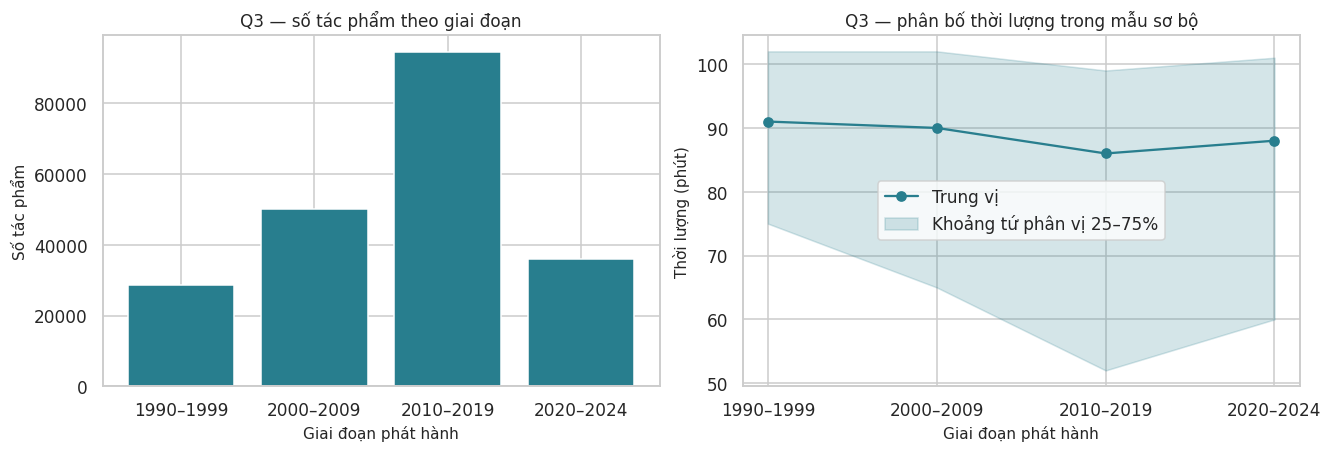

Trung vị thời lượng của giai đoạn 1990–1999 là 91 phút, 2000–2009 là 90 phút, 2010–2019 là 86 phút, 2020–2024 là 88 phút. Mẫu Q3 gồm **209,322 tác phẩm**. Có **24.84%** tác phẩm dưới 60 phút và **41** tác phẩm trên 600 phút. Thành phần tác phẩm và số mẫu giữa các giai đoạn cần được tính đến khi diễn giải xu hướng. Vùng tô trên hình là khoảng tứ phân vị của thời lượng. Bước phân tích Q3 sẽ kiểm tra xu hướng trong các nhóm và lượng hóa độ bất định.

In [15]:
runtime_sample = question_frames['Q3']
runtime_by_period = runtime_sample.groupby('period', observed=True).agg(
    n=('id', 'size'), trung_vi=('runtime', 'median'),
    p25=('runtime', lambda values: values.quantile(.25)),
    p75=('runtime', lambda values: values.quantile(.75)),
    duoi_60_phut=('runtime', lambda values: 100 * values.lt(60).mean()),
    tren_600_phut=('runtime', lambda values: int(values.gt(600).sum())),
)
display(runtime_by_period.round(2))
runtime_genres = runtime_sample[['id', 'period', 'runtime', 'genre_list']].explode('genre_list')
top_runtime_genres = runtime_genres.genre_list.value_counts().head(6).index
runtime_grouped = runtime_genres.groupby(['genre_list', 'period'], observed=True).agg(
    n=('id', 'size'), trung_vi=('runtime', 'median'))
runtime_genre_counts = runtime_grouped['n'].unstack('period').reindex(top_runtime_genres)
runtime_genre_medians = runtime_grouped['trung_vi'].unstack('period').reindex(top_runtime_genres)
display(runtime_genre_counts)
display(runtime_genre_medians)

language_counts = pd.crosstab(runtime_sample.original_language, runtime_sample.period)
display(language_counts.loc[runtime_sample.original_language.value_counts().head(8).index])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
x = np.arange(len(runtime_by_period))
axes[0].bar(x, runtime_by_period['n'], color='#287e8e')
axes[0].set_xticks(x, runtime_by_period.index)
axes[0].set(title='Q3 — số tác phẩm theo giai đoạn', xlabel='Giai đoạn phát hành', ylabel='Số tác phẩm')
axes[1].plot(x, runtime_by_period.trung_vi, 'o-', color='#287e8e', label='Trung vị')
axes[1].fill_between(x, runtime_by_period.p25, runtime_by_period.p75, alpha=.2,
                     color='#287e8e', label='Khoảng tứ phân vị 25–75%')
axes[1].set_xticks(x, runtime_by_period.index)
axes[1].set(title='Q3 — phân bố thời lượng trong mẫu sơ bộ',
            xlabel='Giai đoạn phát hành', ylabel='Thời lượng (phút)')
axes[1].legend()
plt.show()
period_medians_text = ', '.join(
    f'{period} là {row["trung_vi"]:.0f} phút' for period, row in runtime_by_period.iterrows())
display(Markdown(
    f'Trung vị thời lượng của giai đoạn {period_medians_text}. '
    f'Mẫu Q3 gồm **{len(runtime_sample):,} tác phẩm**. '
    f'Có **{runtime_sample.runtime.lt(60).mean():.2%}** tác phẩm dưới 60 phút và '
    f'**{int(runtime_sample.runtime.gt(600).sum()):,}** tác phẩm trên 600 phút. '
    'Thành phần tác phẩm và số mẫu giữa các giai đoạn cần được tính đến khi diễn giải xu hướng. '
    'Vùng tô trên hình là khoảng tứ phân vị của thời lượng. '
    'Bước phân tích Q3 sẽ kiểm tra xu hướng trong các nhóm và lượng hóa độ bất định.'
))

### 6.4. Q4 — Khả năng so sánh các nhóm tài chính

Mẫu Q4 dùng `Released`, năm 1990–2024, ngân sách và doanh thu dương, có thể loại.
Các giá trị được giữ theo CSV để kiểm tra phân phối. Hai mô tả nguồn Kaggle đã đối chiếu
chưa xác minh được đơn vị và phạm vi tài chính của bản v578. Nhãn của hình và bảng vì vậy
ghi rõ giá trị CSV. Kết quả ở đây giúp xem độ phủ và khả năng tạo nhóm cho bước phân tích.

Ba nhóm ngân sách được tạo theo ba phần bằng nhau về thứ hạng ngân sách **trong mỗi giai đoạn**.
Cách chia này là một phương án chẩn đoán số mẫu. Bảng ranh giới ghi giá trị thực và số tác phẩm
để thấy các nhóm của hai giai đoạn có thể mang khoảng ngân sách khác nhau.

,Mô tả mẫu Q4
n,8049.0000
Pearson giá trị CSV,0.7471
Pearson log10,0.8134
Spearman,0.7914


n  budget_min  budget_max
period    budget_group                              
1990–1999 Thấp           456           1     9500000
          Vừa            488    10000000    27000000
          Cao            475    28000000   200000000
2000–2009 Thấp           892           1     6000000
          Vừa            888     6000200    26000000
          Cao            896    27000000   300000000
2010–2019 Thấp          1109           1     3947600
          Vừa           1090     4000000    19800000
          Cao           1159    20000000   379000000
2020–2024 Thấp           192           1     4900000
          Vừa            204     5000000    25900000
          Cao            200    26000000   460000000

period,1990–1999,2000–2009,2010–2019,2020–2024
genre_list,,,,
Drama,650,1322,1578,229
Comedy,564,1001,1160,173
Action,342,617,880,179
Thriller,358,670,822,156
Romance,275,573,520,61
Adventure,206,412,541,130
Crime,270,417,440,70
Horror,141,285,352,108


period       1990–1999           2000–2009           2010–2019            \
budget_group      Thấp  Vừa  Cao      Thấp  Vừa  Cao      Thấp  Vừa  Cao   
genre_list                                                                 
Drama              215  224  211       522  471  329       555  600  423   
Comedy             183  229  152       310  341  350       412  342  406   
Action              75   96  171       130  176  311       175  226  479   
Thriller            90  110  158       155  240  275       238  299  285   
Romance             93  106   76       186  215  172       196  190  134   
Adventure           25   58  123        60   85  267        67  108  366   
Crime               85   92   93       124  143  150       117  148  175   
Horror              62   45   34       110  114   61       144  139   69   

period       2020–2024           
budget_group      Thấp Vừa  Cao  
genre_list                       
Drama               85  90   54  
Comedy              47  59   67  
Action              23  56  100  
Thriller            45  61   50  
Romance             21  29   11  
Adventure           16  35   79  
Crime               12  27   31  
Horror              47  45   16

,n,en_pct
period,,
1990–1999,1419,90.77
2000–2009,2676,75.60
2010–2019,3358,63.34
2020–2024,596,69.13


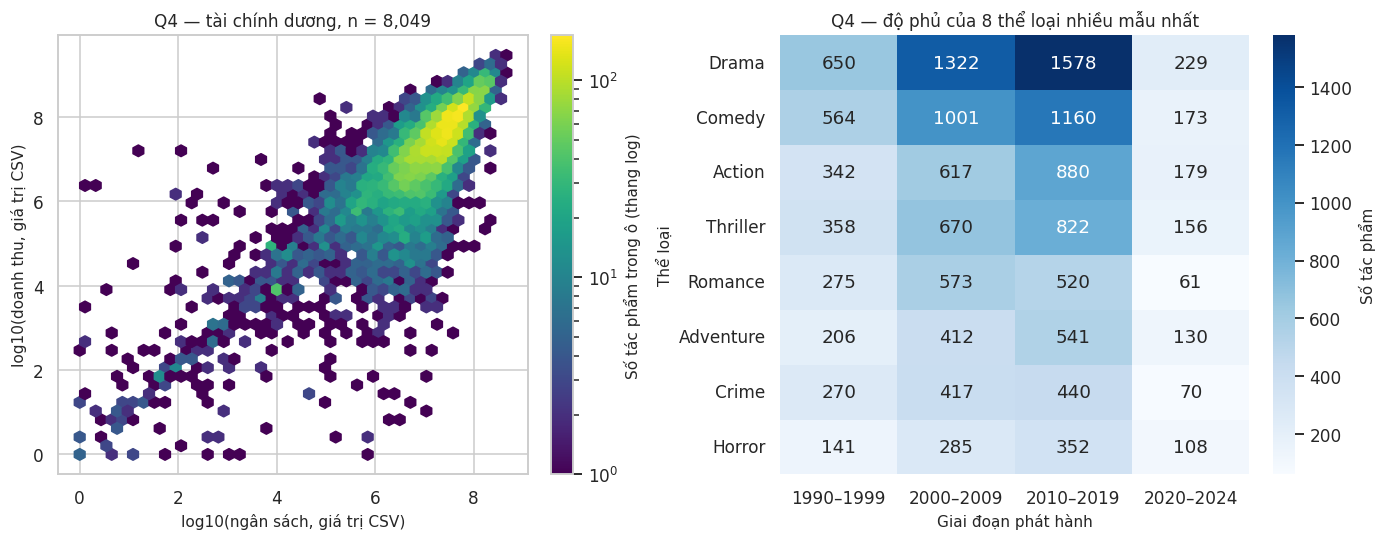

Q4 giữ **8,049 tác phẩm**, tương đương **1.81% raw**. Tỷ lệ ngôn ngữ gốc en là **72.68%**. Trong các ô có quan sát của 8 thể loại hiển thị, số mẫu nhỏ nhất là **11 tác phẩm**. Bảng đếm theo ngân sách, thể loại và giai đoạn cho biết những ô có ít quan sát. Một tác phẩm nhiều thể loại xuất hiện trong nhiều hàng, nên tổng qua các hàng sẽ tính lặp. Q4 cần xác minh tài chính, chọn các nhóm so sánh đủ mẫu và kiểm tra độ nhạy trước khi diễn giải chênh lệch doanh thu giữa các thể loại.

In [16]:
finance = question_frames['Q4'].copy()
finance_log = np.log10(finance[['budget', 'revenue']])
finance_metrics = pd.Series({
    'n': len(finance),
    'Pearson giá trị CSV': finance.budget.corr(finance.revenue),
    'Pearson log10': finance_log.budget.corr(finance_log.revenue),
    'Spearman': finance.budget.corr(finance.revenue, method='spearman'),
}, name='Mô tả mẫu Q4')
display(finance_metrics.to_frame().round(4))
budget_rank = finance.groupby('period', observed=True).budget.rank(method='average', pct=True)
finance['budget_group'] = pd.cut(budget_rank, bins=[0, 1/3, 2/3, 1],
                                 labels=['Thấp', 'Vừa', 'Cao'], include_lowest=True)
budget_ranges = finance.groupby(['period', 'budget_group'], observed=True).agg(
    n=('id', 'size'), budget_min=('budget', 'min'), budget_max=('budget', 'max'))
display(budget_ranges)
finance_genres = finance[['id', 'period', 'budget_group', 'genre_list']].explode('genre_list')
top_finance_genres = finance_genres.genre_list.value_counts().head(8).index
finance_genre_period_counts = pd.crosstab(finance_genres.genre_list, finance_genres.period).reindex(top_finance_genres)
finance_group_counts = finance_genres.groupby(
    ['genre_list', 'period', 'budget_group'], observed=True).id.nunique()
finance_group_counts = finance_group_counts.unstack(['period', 'budget_group']).reindex(top_finance_genres).fillna(0).astype(int)
display(finance_genre_period_counts)
with pd.option_context('display.max_columns', None):
    display(finance_group_counts)

finance_period_profile = finance.groupby('period', observed=True).agg(
    n=('id', 'size'), en_pct=('original_language', lambda values: 100 * values.eq('en').mean()))
display(finance_period_profile.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), layout='constrained')
hb = axes[0].hexbin(finance_log.budget, finance_log.revenue, gridsize=40,
                    mincnt=1, bins='log', cmap='viridis')
axes[0].set(title=f'Q4 — tài chính dương, n = {len(finance):,}',
            xlabel='log10(ngân sách, giá trị CSV)', ylabel='log10(doanh thu, giá trị CSV)')
fig.colorbar(hb, ax=axes[0], label='Số tác phẩm trong ô (thang log)')
sns.heatmap(finance_genre_period_counts, annot=True, fmt='d', cmap='Blues',
            ax=axes[1], cbar_kws={'label': 'Số tác phẩm'})
axes[1].set(title='Q4 — độ phủ của 8 thể loại nhiều mẫu nhất',
            xlabel='Giai đoạn phát hành', ylabel='Thể loại')
plt.show()
display(Markdown(
    f'Q4 giữ **{len(finance):,} tác phẩm**, tương đương **{len(finance)/n:.2%} raw**. '
    f'Tỷ lệ ngôn ngữ gốc en là **{finance.original_language.eq("en").mean():.2%}**. '
    f'Trong các ô có quan sát của 8 thể loại hiển thị, số mẫu nhỏ nhất là '
    f'**{int(finance_group_counts.where(finance_group_counts.gt(0)).min().min())} tác phẩm**. '
    'Bảng đếm theo ngân sách, thể loại và giai đoạn cho biết những ô có ít quan sát. '
    'Một tác phẩm nhiều thể loại xuất hiện trong nhiều hàng, nên tổng qua các hàng sẽ tính lặp. '
    'Q4 cần xác minh tài chính, chọn các nhóm so sánh đủ mẫu và kiểm tra độ nhạy trước khi diễn giải '
    'chênh lệch doanh thu giữa các thể loại.'
))

## 7. Tóm tắt khám phá và hướng tiền xử lý

Năm quan sát dưới đây liên hệ kết quả khám phá với các câu hỏi đã chốt. Số liệu được lấy trực tiếp
từ các bảng trong lần chạy.

In [17]:
notes = [
    f'Định danh cho Q1–Q4. Raw có {n:,} dòng và {movies.shape[1]} cột. '
    f'{int(movies.id.duplicated().sum()):,} dòng dư theo id và '
    f'{int(movies.tconst.duplicated().sum()):,} dòng dư theo tconst. '
    f'Mẫu hai mã duy nhất giữ {len(analysis_base):,} dòng ({len(analysis_base)/n:.2%} raw).',
    f'Độ đầy đủ cho các câu hỏi. Ngày phát hành thiếu ở {int(missing.release_date.sum()):,} dòng '
    f'({missing.release_date.mean():.2%}) và thể loại thiếu ở {int(missing.genres.sum()):,} dòng '
    f'({missing.genres.mean():.2%}). {joint_missing:,} dòng thiếu đồng thời hai trường này.',
    f'Q1 và Q2. Q1 có {int(rating_sensitivity.loc[10, "n"]):,} cặp ở ngưỡng 10 lượt và '
    f'{int(rating_sensitivity.loc[100, "n"]):,} cặp ở ngưỡng 100. '
    f'Q2 có {len(ml_train):,} tác phẩm trước 2020 và {len(ml_test):,} tác phẩm 2020–2024. '
    'Các quy tắc lọc và xử lý đầu vào cần gắn với những phạm vi này.',
    f'Q3. Thời lượng 0 xuất hiện ở {int(movies.runtime.eq(0).sum()):,} dòng raw '
    f'({movies.runtime.eq(0).mean():.2%}). Mẫu Q3 có {len(runtime_sample):,} tác phẩm, '
    f'trong đó {runtime_sample.runtime.lt(60).mean():.2%} ngắn hơn 60 phút. '
    'Cơ cấu tác phẩm theo thể loại, ngôn ngữ và độ dài cần được kiểm tra khi xem xu hướng thời gian.',
    f'Q4. Ngân sách bằng 0 ở {movies.budget.eq(0).mean():.2%} raw, doanh thu bằng 0 ở '
    f'{movies.revenue.eq(0).mean():.2%} raw. Mẫu Q4 giữ {len(finance):,} tác phẩm '
    f'({len(finance)/n:.2%} raw), với {finance.original_language.eq("en").mean():.2%} ngôn ngữ gốc en. '
    'Độ phủ tài chính, đơn vị tiền tệ và số mẫu trong nhóm là các giới hạn quan trọng.',
]
display(Markdown('\n\n'.join(f'{index}. {note}' for index, note in enumerate(notes, 1))))

1. Định danh cho Q1–Q4. Raw có 443,656 dòng và 29 cột. 13,894 dòng dư theo id và 16,995 dòng dư theo tconst. Mẫu hai mã duy nhất giữ 425,189 dòng (95.84% raw).

2. Độ đầy đủ cho các câu hỏi. Ngày phát hành thiếu ở 25,363 dòng (5.72%) và thể loại thiếu ở 83,813 dòng (18.89%). 20,069 dòng thiếu đồng thời hai trường này.

3. Q1 và Q2. Q1 có 55,418 cặp ở ngưỡng 10 lượt và 14,559 cặp ở ngưỡng 100. Q2 có 363,368 tác phẩm trước 2020 và 45,267 tác phẩm 2020–2024. Các quy tắc lọc và xử lý đầu vào cần gắn với những phạm vi này.

4. Q3. Thời lượng 0 xuất hiện ở 61,425 dòng raw (13.85%). Mẫu Q3 có 209,322 tác phẩm, trong đó 24.84% ngắn hơn 60 phút. Cơ cấu tác phẩm theo thể loại, ngôn ngữ và độ dài cần được kiểm tra khi xem xu hướng thời gian.

5. Q4. Ngân sách bằng 0 ở 93.16% raw, doanh thu bằng 0 ở 96.25% raw. Mẫu Q4 giữ 8,049 tác phẩm (1.81% raw), với 72.68% ngôn ngữ gốc en. Độ phủ tài chính, đơn vị tiền tệ và số mẫu trong nhóm là các giới hạn quan trọng.

Các vấn đề chất lượng cần ưu tiên gồm mã lặp, ngày và thể loại thiếu, thời lượng hoặc tài chính
bằng 0, các cực trị cần xác minh, điểm TMDB chưa nhất quán với lượt chấm, nhãn thể loại lặp
và ngày phát hành cần đối chiếu với trạng thái. Những vấn đề này ảnh hưởng khác nhau đến từng câu hỏi.

| Câu hỏi | Hướng tiền xử lý và việc cần giải quyết tiếp |
| --- | --- |
| Chung | Kiểm tra `id`, `tconst` và đơn vị tác phẩm. Mẫu mã duy nhất là phương án đang dùng. Muốn giữ các nhóm lặp cần xác định quy tắc gộp, xử lý xung đột và báo cáo số mẫu. Giữ cờ thiếu, phân biệt số 0 với NA khi kiểm tra. |
| Q1 | Lấy đúng phạm vi 1990–2024, ghép cặp theo tác phẩm, xét điểm cùng lượt chấm, kiểm tra ngưỡng 10/100 và số mẫu có thể loại. Phân tích theo thể loại và khoảng tin cậy thực hiện trong notebook 02. |
| Q2 | Tách phần trước 2020 và phần 2020–2024. Đánh giá cách xử lý thời lượng 0, thể loại, ngôn ngữ thiếu hoặc hiếm. Các phép điền thiếu, mã hóa, chọn tham số học trên tập huấn luyện trong Pipeline của notebook 03. |
| Q3 | Xác định phạm vi độ dài và loại tác phẩm, xử lý thời lượng 0, đối chiếu cực trị. So sánh theo thời gian cần kiểm tra thành phần thể loại và ngôn ngữ. Notebook 02 sẽ lượng hóa mức thay đổi, độ bất định và độ nhạy. |
| Q4 | Xác minh đơn vị, phạm vi và cách chuẩn hóa tài chính của nguồn. Chọn nhóm ngân sách, thời kỳ và thể loại có đủ mẫu. Kiểm tra độ nhạy của ranh giới nhóm, cực trị và ảnh hưởng ngôn ngữ trong notebook 02. |

Các mẫu hình đáng theo dõi là độ phủ cặp điểm khi nâng ngưỡng lượt chấm, sự khác nhau về hồ sơ
giữa hai khoảng thời gian của Q2, phân phối thời lượng và cơ cấu tác phẩm theo giai đoạn của Q3,
cùng sự tập trung và thưa mẫu trong các nhóm tài chính của Q4. Chúng cung cấp căn cứ cho cách
tiền xử lý và phương pháp phân tích sẽ dùng để trả lời các câu hỏi.

In [18]:
# Kiểm tra tính nhất quán của nguồn, các bộ lọc và những bảng dùng để diễn giải.
assert file_sha256(RAW_PATH) == raw_sha256
assert wrong_width_records == 0
assert csv_records - empty_records == n
assert missing.shape == movies.shape
assert missing_table['số thiếu'].between(0, n).all()
assert analysis_base.id.is_unique and analysis_base.tconst.is_unique
for question, mask in question_masks.items():
    assert question_frames[question].index.equals(movies.index[mask])
    assert question_frames[question].index.isin(analysis_base.index).all()
    rows = sample_flow.loc[sample_flow['câu'].eq(question)]
    assert rows['số dòng còn lại'].is_monotonic_decreasing
    assert rows['loại ở bước này'].ge(0).all()
    assert len(analysis_base) - rows['loại ở bước này'].sum() == len(question_frames[question])
assert rating_sensitivity.loc[10, 'n'] == len(q1)
assert rating_sensitivity['n'].is_monotonic_decreasing
assert q1.release_year.between(1990, 2024).all()
assert len(ml_train) + len(ml_test) == len(ml_scope)
assert ml_train.index.intersection(ml_test.index).empty
assert ml_train.release_year.lt(2020).all()
assert ml_test.release_year.between(2020, 2024).all()
assert runtime_sample.runtime.gt(0).all()
assert runtime_by_period['n'].sum() == len(runtime_sample)
assert finance[['budget', 'revenue']].gt(0).all().all()
assert finance.budget_group.notna().all()
assert budget_ranges['n'].sum() == len(finance)
assert finance_period_profile['n'].sum() == len(finance)
assert outlier_audit['số cờ IQR'].between(0, outlier_audit['n']).all()
assert outlier_audit['số cờ z'].between(0, outlier_audit['số z hợp lệ']).all()
assert outlier_audit['số z hợp lệ'].between(0, outlier_audit['n']).all()
assert corr_matrix.shape == (8, 8)
assert correlation_sample.index.is_unique
assert correlation_sample.index.isin(question_frames['Q4'].index).all()
assert np.isfinite(correlation_sample).all().all()
assert corr_flow['số tác phẩm'].is_monotonic_decreasing
assert corr_flow['số tác phẩm'].iloc[0] - corr_flow['loại thêm'].sum() == len(correlation_sample)
assert np.allclose(corr_matrix, corr_matrix.T)
assert np.allclose(np.diag(corr_matrix), 1)
assert corr_matrix.abs().le(1).all().all()
assert len(notes) == 5
print('Đã kiểm tra nguồn và các mẫu Q1–Q4. SHA-256 CSV khớp trước, sau chạy.')

Đã kiểm tra nguồn và các mẫu Q1–Q4. SHA-256 CSV khớp trước, sau chạy.
